# Sankalp — Lesion Triage Model Training (Kaggle)

Trains the **refer / no-refer** lesion model that powers the screening app, then exports everything the backend needs
(ONNX + INT8 models, model contract, model card, out-of-distribution stats, reference embeddings, benchmark set).

**Before running:** Settings → Accelerator **GPU T4 x2** (or P100) · Internet **On** · Add Data: the code dataset +
image datasets listed in the README · (optional) Add-ons → Secrets → `ROBOFLOW_API_KEY`.

Run with **Save Version → Save & Run All (Commit)** so it keeps running even if you close the tab.

## 1. Settings

In [ ]:
# ---- change these only if you need to ----
FAST_MODE = False        # True = skip 5-fold cross-validation (saves ~45-60 min; test metrics are still computed)
IMAGE_SIZE = 224         # model input size
EPOCHS = 22

## 2. Setup — install extras and locate the code

In [ ]:
!pip install -q imagehash onnx onnxruntime roboflow 2>&1 | tail -1
import os, sys, glob, shutil, json
os.environ["NO_ALBUMENTATIONS_UPDATE"] = "1"

hits = glob.glob("/kaggle/input/**/oralscreen/pipeline.py", recursive=True)
assert hits, "Code dataset not found — upload oralscreen-phase1.zip as a Kaggle Dataset and Add Data to this notebook"
src_root = os.path.dirname(os.path.dirname(hits[0]))
CODE = "/kaggle/working/oralscreen-phase1"
if os.path.exists(CODE):
    shutil.rmtree(CODE)
shutil.copytree(src_root, CODE)
sys.path.insert(0, CODE)
code_dataset = os.path.relpath(src_root, "/kaggle/input").split(os.sep)
print("code found in:", src_root)

import torch
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE — enable GPU!")

## 3. Roboflow key (optional — leukoplakia + ulcer sets)

In [ ]:
try:
    from kaggle_secrets import UserSecretsClient
    os.environ["ROBOFLOW_API_KEY"] = UserSecretsClient().get_secret("ROBOFLOW_API_KEY")
    print("Roboflow key loaded")
except Exception as e:
    print("No Roboflow key — continuing with Kaggle datasets only")

## 4. Build the configuration

In [ ]:
from oralscreen.utils import load_config
from oralscreen.pipeline import Pipeline, STAGES

overrides = {
    "paths": {"code_dataset_names": ["oralscreen-code", "oralscreen-phase1"] + code_dataset},
    "data": {"image_size": IMAGE_SIZE},
    "train": {"epochs": EPOCHS, "run_cv_on_best": not FAST_MODE,
              "num_workers": min(4, os.cpu_count() or 2)},
}
cfg = load_config(f"{CODE}/config.yaml", overrides)
pipe = Pipeline(cfg)

## 5. Scan the datasets — CHECK THIS TABLE

Every folder found, the label it was mapped to, and why. `excluded` and `unknown` folders are not used.
If a folder is labelled wrongly, edit the keyword lists in `config.yaml` (section `labels`) and re-run.

In [ ]:
import pandas as pd
pd.set_option("display.max_rows", 300, "display.max_colwidth", 80)
pipe.run(["scan"])
pd.read_csv(f"{cfg['paths']['work_dir']}/reports/scan_report.csv")

In [23]:
import inspect
from oralscreen import pipeline

print("PIPELINE FILE:")
print(inspect.getfile(pipeline))

print("\nAVAILABLE STAGES:")
print(STAGES)

print("\nPIPELINE METHODS:")
for name, obj in inspect.getmembers(Pipeline, inspect.isfunction):
    print(name, inspect.signature(obj))

PIPELINE FILE:
/kaggle/working/oralscreen-phase1/oralscreen/pipeline.py

AVAILABLE STAGES:
['scan', 'clean', 'split', 'select', 'cv', 'final', 'evaluate', 'export', 'verify', 'package']

PIPELINE METHODS:
__init__ (self, cfg: 'dict')
_benchmark (self, te)
_best_cand (self)
_embeddings (self, net, frame)
_fold (self, df, k)
_load_df (self, name: 'str') -> 'pd.DataFrame'
_load_final (self)
_model_card (self, contract, ck)
_ood_and_reference (self, df, net)
_pool (self, df)
_save_df (self, df: 'pd.DataFrame', name: 'str')
_y (self, df)
clean (self)
cv (self)
evaluate (self)
export (self)
final (self)
package (self)
run (self, stages)
scan (self) -> 'pd.DataFrame'
select (self)
split (self)
verify (self)


In [24]:
import inspect
from oralscreen.pipeline import Pipeline

print("=" * 70)
print("CLEAN METHOD")
print("=" * 70)
print(inspect.getsource(Pipeline.clean))

print("\n" + "=" * 70)
print("SPLIT METHOD")
print("=" * 70)
print(inspect.getsource(Pipeline.split))

print("\n" + "=" * 70)
print("FOLD METHOD")
print("=" * 70)
print(inspect.getsource(Pipeline._fold))

CLEAN METHOD
    def clean(self):
        df = self._load_df("manifest_raw")
        with timed("validate images + group duplicates"):
            df = inspect_images(df, self.cfg["data"]["min_side"])
            df = group_duplicates(df, self.cfg, self.device)
            df["rep"] = choose_representatives(df)
            df = build_cache(df, self.work / "image_cache", int(self.cfg["data"].get("cache_max_side", 512)))
            stats = dict(df.attrs.get("dedupe_stats", {}))
            stats["unique_after_grouping_by_label"] = df[df.rep].label.value_counts().to_dict()
            stats["unique_per_source"] = df[df.rep].groupby(["source", "label"]).size().unstack(fill_value=0).to_dict()
            save_json(stats, self.reports / "dedupe_stats.json")
            LOG.info("Unique photos after grouping: %s", stats["unique_after_grouping_by_label"])
            self._save_df(df, "manifest_clean")


SPLIT METHOD
    def split(self):
        df = make_splits(self._load_df("manifest_clean"

In [28]:
import inspect
import oralscreen.pipeline as p

# Find the module where make_splits is defined
print("MAKE_SPLITS LOCATION:")
print(p.make_splits.__module__ if hasattr(p, "make_splits") else "Not directly in pipeline module")

# Inspect the global functions used by Pipeline.split and Pipeline.clean
for method_name in ["split", "clean"]:
    method = getattr(p.Pipeline, method_name)

    print(f"\n{'='*60}")
    print(f"FUNCTIONS REFERENCED BY {method_name.upper()}")
    print("="*60)

    for name in method.__code__.co_names:
        obj = method.__globals__.get(name)

        if callable(obj) and hasattr(obj, "__module__"):
            print(f"\n{name}: {obj.__module__}")

            try:
                print(inspect.getsource(obj))
            except (OSError, TypeError):
                print("Source unavailable")

MAKE_SPLITS LOCATION:
oralscreen.splits

FUNCTIONS REFERENCED BY SPLIT

make_splits: oralscreen.splits
def make_splits(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    seed = cfg["project"]["seed"]
    scfg = cfg["split"]
    df = df.copy().reset_index(drop=True)
    df["split"] = "dev"
    test_mask = _holdout(df, scfg["test_fraction"], seed)
    df.loc[test_mask, "split"] = "test"

    dev = df[df["split"] == "dev"]
    calib_mask = _holdout(dev, scfg["calib_fraction"], seed + 1)
    df.loc[dev.index[calib_mask], "split"] = "calib"

    # CV folds over the full dev pool (dev + calib) for robust estimates
    pool = df[df["split"].isin(["dev", "calib"])]
    sgkf = StratifiedGroupKFold(n_splits=scfg["n_folds"], shuffle=True, random_state=seed + 2)
    df["fold"] = -1
    for k, (_, val_idx) in enumerate(sgkf.split(pool, _strat_key(pool), groups=pool["group"].values)):
        df.loc[pool.index[val_idx], "fold"] = k

    # sanity: no group crosses test/dev
    g_test = set(df.loc[df["

## 6. Clean, deduplicate, split

In [29]:
pipe.run(["clean", "split"])
print(json.dumps(json.load(open(f"{cfg['paths']['work_dir']}/reports/dedupe_stats.json")), indent=2)[:3000])
pd.read_csv(f"{cfg['paths']['work_dir']}/reports/split_table.csv")

08:46:18 | INFO    | ▶ validate images + group duplicates


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

08:50:38 | INFO    | Duplicate grouping: {'md5': 798, 'phash_pairs_confirmed': 2738, 'phash_pairs_rejected_by_pixel_check': 125, 'embedding_pairs': 1982, 'images': 8346, 'groups': 6669, 'conflicting_groups': 8, 'images_in_conflicting_groups': 33}
08:50:38 | WARNING | 8 groups contain the same photo with BOTH labels — these images are removed.
08:51:03 | INFO    | Unique photos after grouping: {'no_refer': 3439, 'refer': 3222}
08:51:04 | INFO    | ✔ validate images + group duplicates (286.0s)
08:51:10 | INFO    | Split sizes (images): {'dev': 6096, 'test': 1186, 'calib': 1031}
08:51:10 | INFO    | Label balance per split:
label  no_refer  refer
split                 
calib       514    517
dev        3063   3033
test        604    582


{
  "md5": 798,
  "phash_pairs_confirmed": 2738,
  "phash_pairs_rejected_by_pixel_check": 125,
  "embedding_pairs": 1982,
  "images": 8346,
  "groups": 6669,
  "conflicting_groups": 8,
  "images_in_conflicting_groups": 33,
  "unique_after_grouping_by_label": {
    "no_refer": 3439,
    "refer": 3222
  },
  "unique_per_source": {
    "no_refer": {
      "Teeth_Dataset": 2645,
      "mohitmural/oral-cancer-lips-and-tongue": 40,
      "roboflow:aadith/ulcer_detection-12cr0": 101,
      "roboflow:makhluk/leukoplakia-8woh8": 0,
      "roboflow:oral-cancer-emoot/leukoplakia": 0,
      "roboflow:oral-dquwv/oralleukoplakia": 0,
      "salmansajid05/oral-diseases": 206,
      "zaidpy/oral-cancer-dataset": 447
    },
    "refer": {
      "Teeth_Dataset": 2229,
      "mohitmural/oral-cancer-lips-and-tongue": 50,
      "roboflow:aadith/ulcer_detection-12cr0": 0,
      "roboflow:makhluk/leukoplakia-8woh8": 214,
      "roboflow:oral-cancer-emoot/leukoplakia": 35,
      "roboflow:oral-dquwv/oralleuko

,split,rep,no_refer,refer
0,calib,False,91,125
1,calib,True,423,392
2,dev,False,539,663
3,dev,True,2524,2370
4,test,False,112,122
5,test,True,492,460


In [30]:
%%writefile /kaggle/working/oralscreen-phase1/oralscreen/splits.py
"""Group-aware, stratified splits with train-only sources."""
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

from .utils import LOG


def _strat_key(df: pd.DataFrame) -> np.ndarray:
    key = df["label"].astype(str) + "|" + df["source"].astype(str)
    vc = key.value_counts()
    rare = key.map(vc) < 10
    key = key.where(~rare, df["label"].astype(str))
    return key.values


def _holdout(df: pd.DataFrame, frac: float, seed: int) -> np.ndarray:
    n_splits = max(2, int(round(1.0 / frac)))
    sgkf = StratifiedGroupKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=seed
    )
    _, hold_idx = next(
        sgkf.split(df, _strat_key(df), groups=df["group"].values)
    )
    mask = np.zeros(len(df), dtype=bool)
    mask[hold_idx] = True
    return mask


def train_only_mask(df: pd.DataFrame, patterns: list[str]) -> np.ndarray:
    if not patterns:
        return np.zeros(len(df), dtype=bool)

    pats = [p.lower() for p in patterns]

    hit = df["source"].astype(str).str.lower().apply(
        lambda s: any(p in s for p in pats)
    )

    bad_groups = set(df.loc[hit, "group"])
    return df["group"].isin(bad_groups).values


def make_splits(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    seed = cfg["project"]["seed"]
    scfg = cfg["split"]

    df = df.copy().reset_index(drop=True)
    df["split"] = "dev"
    df["fold"] = -1

    df["train_only"] = train_only_mask(
        df, scfg.get("train_only_sources") or []
    )

    if df["train_only"].any():
        LOG.info(
            "Train-only images (never evaluated): %d from %s",
            int(df["train_only"].sum()),
            df.loc[df["train_only"], "source"].value_counts().to_dict()
        )

    ev = df[~df["train_only"]]

    if ev.empty:
        raise SystemExit("Every source is train-only — nothing left to evaluate on.")

    test_mask = _holdout(ev, scfg["test_fraction"], seed)
    df.loc[ev.index[test_mask], "split"] = "test"

    ev_dev = df[(df["split"] == "dev") & ~df["train_only"]]

    calib_mask = _holdout(
        ev_dev, scfg["calib_fraction"], seed + 1
    )
    df.loc[ev_dev.index[calib_mask], "split"] = "calib"

    pool = df[
        df["split"].isin(["dev", "calib"]) & ~df["train_only"]
    ]

    sgkf = StratifiedGroupKFold(
        n_splits=scfg["n_folds"],
        shuffle=True,
        random_state=seed + 2
    )

    for k, (_, val_idx) in enumerate(
        sgkf.split(
            pool,
            _strat_key(pool),
            groups=pool["group"].values
        )
    ):
        df.loc[pool.index[val_idx], "fold"] = k

    g_test = set(df.loc[df["split"] == "test", "group"])
    g_rest = set(df.loc[df["split"] != "test", "group"])

    assert not (g_test & g_rest), "Group leakage between test and dev"

    assert not df.loc[df["train_only"], "split"].isin(
        ["test", "calib"]
    ).any(), "Train-only image in evaluation"

    LOG.info("Split sizes (images): %s", df["split"].value_counts().to_dict())
    LOG.info("Label balance per split:\n%s", pd.crosstab(df["split"], df["label"]))

    LOG.info(
        "Evaluation sources in test (unique photos):\n%s",
        df[(df["split"] == "test") & df["rep"]]
        .groupby(["source", "label"])
        .size()
        .unstack(fill_value=0)
    )

    return df

Overwriting /kaggle/working/oralscreen-phase1/oralscreen/splits.py


In [31]:
import importlib
import oralscreen.splits
import oralscreen.pipeline

# Reload the updated split logic
importlib.reload(oralscreen.splits)
importlib.reload(oralscreen.pipeline)

from oralscreen.pipeline import Pipeline

# MOD will be used exclusively for training
cfg["split"]["train_only_sources"] = [
    "teeth_dataset",
    "mod-mouth-oral-diseases",
    "mouth-and-oral-diseases"
]

# Increase test fraction for the remaining evaluation datasets
cfg["split"]["test_fraction"] = 0.20

# Rebuild splits using existing cleaned data
pipe = Pipeline(cfg)
pipe.run(["split"])

# Read the new split manifest
df = pd.read_pickle(
    f"{cfg['paths']['work_dir']}/manifest_split.pkl"
)

print("\n========== VERIFICATION ==========")

print("Total train-only images:", int(df["train_only"].sum()))

print(
    "Train-only images in test/calibration:",
    int(
        df[
            df["train_only"] &
            df["split"].isin(["test", "calib"])
        ].shape[0]
    )
)

print("\nTest set by source:")
print(
    df[
        (df["split"] == "test") & df["rep"]
    ]
    .groupby(["source", "label"])
    .size()
    .unstack(fill_value=0)
)

print("\nFinal split counts:")
print(pd.crosstab(df["split"], df["label"]))

print("\n=================================")

09:04:53 | INFO    | OralScreen Phase 1 v1.0.0 | torch 2.11.0+cu130 | device cuda | python 3.13.16
09:04:53 | INFO    | Train-only images (never evaluated): 5418 from {'Teeth_Dataset': 5132, 'zaidpy/oral-cancer-dataset': 157, 'mohitmural/oral-cancer-lips-and-tongue': 65, 'roboflow:oral-dquwv/oralleukoplakia': 33, 'salmansajid05/oral-diseases': 24, 'roboflow:oral-cancer-emoot/leukoplakia': 3, 'roboflow:aadith/ulcer_detection-12cr0': 3, 'roboflow:makhluk/leukoplakia-8woh8': 1}
09:04:55 | INFO    | Split sizes (images): {'dev': 7393, 'test': 587, 'calib': 333}
09:04:55 | INFO    | Label balance per split:
label  no_refer  refer
split                 
calib       150    183
dev        3748   3645
test        283    304
09:04:55 | INFO    | Evaluation sources in test (unique photos):
label                                   no_refer  refer
source                                                 
mohitmural/oral-cancer-lips-and-tongue         9      2
roboflow:aadith/ulcer_detection-12cr0     


========== VERIFICATION ==========
Total train-only images: 5418
Train-only images in test/calibration: 0

Test set by source:
label                                   no_refer  refer
source                                                 
mohitmural/oral-cancer-lips-and-tongue         9      2
roboflow:aadith/ulcer_detection-12cr0         21      0
roboflow:makhluk/leukoplakia-8woh8             0     43
roboflow:oral-cancer-emoot/leukoplakia         0      8
roboflow:oral-dquwv/oralleukoplakia            0     37
salmansajid05/oral-diseases                   40      0
zaidpy/oral-cancer-dataset                    88     97

Final split counts:
label  no_refer  refer
split                 
calib       150    183
dev        3748   3645
test        283    304



In [32]:
# Inspect non-MOD images excluded because of train-only grouping

excluded = df[
    df["train_only"] &
    ~df["source"].astype(str).str.contains(
        "Teeth_Dataset|mod-mouth-oral-diseases|mouth-and-oral-diseases",
        case=False,
        na=False
    )
]

print("Non-MOD images marked train-only:", len(excluded))

print("\nBreakdown by source:")
print(excluded["source"].value_counts())

print("\nBreakdown by source and label:")
print(pd.crosstab(excluded["source"], excluded["label"]))

print("\nRepresentative/non-representative breakdown:")
print(pd.crosstab(excluded["source"], excluded["rep"]))

Non-MOD images marked train-only: 286

Breakdown by source:
source
zaidpy/oral-cancer-dataset                157
mohitmural/oral-cancer-lips-and-tongue     65
roboflow:oral-dquwv/oralleukoplakia        33
salmansajid05/oral-diseases                24
roboflow:oral-cancer-emoot/leukoplakia      3
roboflow:aadith/ulcer_detection-12cr0       3
roboflow:makhluk/leukoplakia-8woh8          1
Name: count, dtype: int64

Breakdown by source and label:
label                                   no_refer  refer
source                                                 
mohitmural/oral-cancer-lips-and-tongue         0     65
roboflow:aadith/ulcer_detection-12cr0          3      0
roboflow:makhluk/leukoplakia-8woh8             0      1
roboflow:oral-cancer-emoot/leukoplakia         0      3
roboflow:oral-dquwv/oralleukoplakia            0     33
salmansajid05/oral-diseases                   24      0
zaidpy/oral-cancer-dataset                     0    157

Representative/non-representative breakdown:
rep

In [33]:
# Find groups containing both MOD and non-MOD images

mod_mask = df["source"].astype(str).str.contains(
    "Teeth_Dataset|mod-mouth-oral-diseases|mouth-and-oral-diseases",
    case=False,
    na=False
)

mod_groups = set(df.loc[mod_mask, "group"])

shared = df[df["group"].isin(mod_groups)].copy()

print("Total groups containing MOD:", len(mod_groups))
print("Total images in those groups:", len(shared))

print("\nImages per source in shared groups:")
print(shared["source"].value_counts())

print("\nShared groups by source and label:")
print(
    shared.groupby(["source", "label"])
    .agg(
        images=("group", "size"),
        groups=("group", "nunique"),
        representatives=("rep", "sum")
    )
)

print("\nSample shared groups (first 15):")
for group_id, g in list(shared.groupby("group"))[:15]:
    print("\nGROUP:", group_id)
    print(g[["source", "label", "rep", "path"]].to_string(index=False))

Total groups containing MOD: 4934
Total images in those groups: 5418

Images per source in shared groups:
source
Teeth_Dataset                             5132
zaidpy/oral-cancer-dataset                 157
mohitmural/oral-cancer-lips-and-tongue      65
roboflow:oral-dquwv/oralleukoplakia         33
salmansajid05/oral-diseases                 24
roboflow:oral-cancer-emoot/leukoplakia       3
roboflow:aadith/ulcer_detection-12cr0        3
roboflow:makhluk/leukoplakia-8woh8           1
Name: count, dtype: int64

Shared groups by source and label:
                                                 images  groups  \
source                                 label                      
Teeth_Dataset                          no_refer    2794    2651   
                                       refer       2338    2283   
mohitmural/oral-cancer-lips-and-tongue refer         65      46   
roboflow:aadith/ulcer_detection-12cr0  no_refer       3       1   
roboflow:makhluk/leukoplakia-8woh8     refer   

In [34]:
print("Training-related functions:")

import inspect
from oralscreen.pipeline import Pipeline

for name in ["_pool", "_fold"]:
    if hasattr(Pipeline, name):
        print(f"\n========== {name} ==========")
        print(inspect.getsource(getattr(Pipeline, name)))

Training-related functions:

========== _pool ==========
    def _pool(self, df):
        return df[df["split"].isin(["dev", "calib"])]


========== _fold ==========
    def _fold(self, df, k):
        pool = self._pool(df)
        tr = pool[pool["fold"] != k]
        va = pool[(pool["fold"] == k) & pool["rep"]]
        return tr, va



## 7. Compare backbones (fold 0) and pick the best

In [35]:
pipe.run(["select"])

selection = pd.read_csv(
    f"{cfg['paths']['work_dir']}/reports/candidate_selection.csv"
)

display(selection)

09:16:39 | INFO    | ▶ candidate convnext_tiny (fold 0)
09:17:08 | INFO    | convnext_tiny ep 01/22  loss 0.6016  val AUC 0.8942  bAcc@0.5 0.7907  (28s)
09:17:31 | INFO    | convnext_tiny ep 02/22  loss 0.5449  val AUC 0.9068  bAcc@0.5 0.8203  (24s)
09:18:24 | INFO    | convnext_tiny ep 03/22  loss 0.4999  val AUC 0.9379  bAcc@0.5 0.8480  (53s)
09:19:07 | INFO    | convnext_tiny ep 04/22  loss 0.3751  val AUC 0.9509  bAcc@0.5 0.8673  (43s)
09:19:51 | INFO    | convnext_tiny ep 05/22  loss 0.3499  val AUC 0.9575  bAcc@0.5 0.8928  (43s)
09:20:34 | INFO    | convnext_tiny ep 06/22  loss 0.3193  val AUC 0.9549  bAcc@0.5 0.9010  (43s)
09:21:17 | INFO    | convnext_tiny ep 07/22  loss 0.2658  val AUC 0.9594  bAcc@0.5 0.9042  (43s)
09:22:01 | INFO    | convnext_tiny ep 08/22  loss 0.2678  val AUC 0.9641  bAcc@0.5 0.8986  (43s)
09:22:44 | INFO    | convnext_tiny ep 09/22  loss 0.2560  val AUC 0.9695  bAcc@0.5 0.9051  (43s)
09:23:27 | INFO    | convnext_tiny ep 10/22  loss 0.2426  val AUC 0.970

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.5MB            

model.safetensors: downloading bytes:           |  0.00B            

09:32:41 | INFO    | effnetv2_s ep 01/22  loss 0.6183  val AUC 0.8492  bAcc@0.5 0.7315  (30s)
09:33:09 | INFO    | effnetv2_s ep 02/22  loss 0.5529  val AUC 0.8589  bAcc@0.5 0.7550  (27s)
09:34:10 | INFO    | effnetv2_s ep 03/22  loss 0.4222  val AUC 0.9446  bAcc@0.5 0.8504  (61s)
09:35:01 | INFO    | effnetv2_s ep 04/22  loss 0.3442  val AUC 0.9679  bAcc@0.5 0.9206  (51s)
09:35:52 | INFO    | effnetv2_s ep 05/22  loss 0.3200  val AUC 0.9697  bAcc@0.5 0.9127  (51s)
09:36:44 | INFO    | effnetv2_s ep 06/22  loss 0.3073  val AUC 0.9681  bAcc@0.5 0.9182  (51s)
09:37:35 | INFO    | effnetv2_s ep 07/22  loss 0.2835  val AUC 0.9641  bAcc@0.5 0.9150  (51s)
09:38:27 | INFO    | effnetv2_s ep 08/22  loss 0.2618  val AUC 0.9744  bAcc@0.5 0.9182  (51s)
09:39:19 | INFO    | effnetv2_s ep 09/22  loss 0.2651  val AUC 0.9739  bAcc@0.5 0.9247  (52s)
09:40:10 | INFO    | effnetv2_s ep 10/22  loss 0.2660  val AUC 0.9769  bAcc@0.5 0.9305  (52s)
09:41:02 | INFO    | effnetv2_s ep 11/22  loss 0.2549  val A

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

09:50:56 | INFO    | dinov2_s ep 01/22  loss 0.6349  val AUC 0.8571  bAcc@0.5 0.7745  (24s)
09:51:20 | INFO    | dinov2_s ep 02/22  loss 0.5728  val AUC 0.8749  bAcc@0.5 0.7942  (24s)
09:52:02 | INFO    | dinov2_s ep 03/22  loss 0.5755  val AUC 0.9119  bAcc@0.5 0.8217  (42s)
09:52:44 | INFO    | dinov2_s ep 04/22  loss 0.4698  val AUC 0.9361  bAcc@0.5 0.8480  (41s)
09:53:26 | INFO    | dinov2_s ep 05/22  loss 0.4089  val AUC 0.9366  bAcc@0.5 0.8448  (42s)
09:54:07 | INFO    | dinov2_s ep 06/22  loss 0.3649  val AUC 0.9466  bAcc@0.5 0.8890  (41s)
09:54:49 | INFO    | dinov2_s ep 07/22  loss 0.3543  val AUC 0.9472  bAcc@0.5 0.8908  (42s)
09:55:31 | INFO    | dinov2_s ep 08/22  loss 0.3352  val AUC 0.9489  bAcc@0.5 0.9031  (42s)
09:56:13 | INFO    | dinov2_s ep 09/22  loss 0.3239  val AUC 0.9442  bAcc@0.5 0.9113  (42s)
09:56:54 | INFO    | dinov2_s ep 10/22  loss 0.2955  val AUC 0.9435  bAcc@0.5 0.9031  (42s)
09:57:36 | INFO    | dinov2_s ep 11/22  loss 0.2873  val AUC 0.9426  bAcc@0.5 0.

,key,auc,balanced_accuracy@opt,sensitivity@opt,specificity@opt,best_epoch
0,effnetv2_s,0.979456,0.943884,0.961538,0.926230,16
1,convnext_tiny,0.977117,0.940153,0.929487,0.950820,18
2,dinov2_s,0.948928,0.914145,0.910256,0.918033,8
3,dinov2_s_probe,0.887400,0.825662,0.692308,0.959016,0


## 8. Cross-validation of the chosen backbone (skipped in FAST_MODE)

In [ ]:
pipe.run(["cv"])

p = f"{cfg['paths']['work_dir']}/reports/cross_validation.csv"

pd.read_csv(p) if os.path.exists(p) else "CV skipped"

## 9. Train the final model, calibrate, evaluate on the held-out test set

In [ ]:
pipe.run(["final", "evaluate"])
m = json.load(open(f"{cfg['paths']['work_dir']}/reports/test_metrics.json"))
rows = []
for name in ("balanced", "screening"):
    t = m["test"][name]
    rows.append({"operating point": name, "threshold": round(t["threshold"], 3), "accuracy": t["accuracy"],
                 "balanced accuracy": t["balanced_accuracy"], "sensitivity": t["sensitivity"],
                 "specificity": t["specificity"], "AUC": t.get("auc"), "F1": t["f1"],
                 "accuracy 95% CI": t["ci95"].get("accuracy"), "sensitivity 95% CI": t["ci95"].get("sensitivity")})
print("Held-out test set:", m["n_test_unique_photos"], "unique photos")
pd.DataFrame(rows)

In [ ]:
from IPython.display import Image, display
R = f"{cfg['paths']['work_dir']}/reports"
for f in ["roc_test.png", "confusion_balanced.png", "confusion_screening.png", "calibration_test.png",
          "heatmaps_test.png", "history_final.png"]:
    if os.path.exists(f"{R}/{f}"):
        print(f); display(Image(f"{R}/{f}"))
pd.read_csv(f"{R}/per_source_test.csv")

## 10. Export ONNX + INT8, verify, package

In [ ]:
pipe.run(["export", "verify", "package"])
print(json.dumps(json.load(open(f"{cfg['paths']['work_dir']}/reports/artifact_verification.json")), indent=2))
from IPython.display import FileLink
FileLink("oralscreen_artifacts.zip")

In [1]:
import os
from pathlib import Path

print("=" * 65)
print("ORALSCREEN — RECOVERY CHECK")
print("=" * 65)

paths = [
    "/kaggle/working/oralscreen",
    "/kaggle/working/oralscreen/reports",
    "/kaggle/working/oralscreen/checkpoints",
    "/kaggle/working/oralscreen-phase1",
    "/kaggle/input",
]

for p in paths:
    path = Path(p)
    print(f"\n{'EXISTS' if path.exists() else 'MISSING'}: {p}")

    if path.exists() and path.is_dir():
        files = list(path.iterdir())
        print(f"Items: {len(files)}")
        for f in files[:20]:
            print("  ", f.name)

print("\n" + "=" * 65)
print("SEARCHING FOR PREVIOUS CV RESULTS")
print("=" * 65)

for root in [Path("/kaggle/working"), Path("/kaggle/input")]:
    for p in root.rglob("*"):
        if p.is_file() and (
            "cross_validation" in p.name.lower()
            or "candidate_selection" in p.name.lower()
            or "effnetv2" in p.name.lower()
            or "cv_fold" in p.name.lower()
        ):
            print(p)

ORALSCREEN — RECOVERY CHECK

MISSING: /kaggle/working/oralscreen

MISSING: /kaggle/working/oralscreen/reports

MISSING: /kaggle/working/oralscreen/checkpoints

MISSING: /kaggle/working/oralscreen-phase1

EXISTS: /kaggle/input
Items: 2
   datasets
   notebooks

SEARCHING FOR PREVIOUS CV RESULTS


In [2]:
from pathlib import Path

for root in [
    Path("/kaggle/input/datasets"),
    Path("/kaggle/input/notebooks"),
]:
    print(f"\n{'='*60}")
    print(root)
    print("="*60)

    if root.exists():
        for item in root.iterdir():
            print(item.name, " [DIR]" if item.is_dir() else " [FILE]")


/kaggle/input/datasets
zaidpy  [DIR]
mohitmural  [DIR]
salmansajid05  [DIR]

/kaggle/input/notebooks
shivam17299  [DIR]


In [3]:
from pathlib import Path

for base in [
    Path("/kaggle/input/datasets"),
    Path("/kaggle/input/notebooks"),
]:
    print(f"\n{'='*65}\n{base}\n{'='*65}")

    for p in sorted(base.rglob("*")):
        depth = len(p.relative_to(base).parts)
        if depth <= 3:
            kind = "DIR " if p.is_dir() else "FILE"
            print(f"{kind} {p}")


/kaggle/input/datasets
DIR  /kaggle/input/datasets/mohitmural
DIR  /kaggle/input/datasets/mohitmural/oral-cancer-lips-and-tongue
DIR  /kaggle/input/datasets/mohitmural/oral-cancer-lips-and-tongue/OralCancer
DIR  /kaggle/input/datasets/mohitmural/oralscreen-code
FILE /kaggle/input/datasets/mohitmural/oralscreen-code/README.md
FILE /kaggle/input/datasets/mohitmural/oralscreen-code/config.yaml
DIR  /kaggle/input/datasets/mohitmural/oralscreen-code/oralscreen
FILE /kaggle/input/datasets/mohitmural/oralscreen-code/requirements.txt
DIR  /kaggle/input/datasets/salmansajid05
DIR  /kaggle/input/datasets/salmansajid05/oral-diseases
DIR  /kaggle/input/datasets/salmansajid05/oral-diseases/Calculus
DIR  /kaggle/input/datasets/salmansajid05/oral-diseases/Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset
DIR  /kaggle/input/datasets/salmansajid05/oral-diseases/Data caries
DIR  /kaggle/input/datasets/salmansajid05/oral-diseases/Gingivitis
DIR  /kaggle/input/datasets/salmansajid05/oral-

In [4]:
from pathlib import Path

CODE = Path("/kaggle/input/datasets/mohitmural/oralscreen-code")

print("ORALSCREEN SOURCE FILES")
print("=" * 55)

for p in sorted((CODE / "oralscreen").rglob("*")):
    if p.is_file():
        print(p.relative_to(CODE))

ORALSCREEN SOURCE FILES
oralscreen/__init__.py
oralscreen/data.py
oralscreen/dedupe.py
oralscreen/engine.py
oralscreen/export.py
oralscreen/imaging.py
oralscreen/inference_reference.py
oralscreen/metrics.py
oralscreen/models.py
oralscreen/pipeline.py
oralscreen/plots.py
oralscreen/sources.py
oralscreen/splits.py
oralscreen/utils.py


In [5]:
import shutil
import sys
from pathlib import Path

SOURCE = Path("/kaggle/input/datasets/mohitmural/oralscreen-code")
CODE = Path("/kaggle/working/oralscreen-phase1")
WORK = Path("/kaggle/working/oralscreen")

shutil.copytree(SOURCE, CODE, dirs_exist_ok=True)
WORK.mkdir(parents=True, exist_ok=True)

if str(CODE) not in sys.path:
    sys.path.insert(0, str(CODE))

print("Source restored:", CODE.exists())
print("Working directory:", WORK.exists())
print("Package files:", len(list((CODE / "oralscreen").glob("*.py"))))

# Check whether the saved split code already contains our MOD correction
split_code = (CODE / "oralscreen" / "splits.py").read_text()

print("\nTrain-only logic already present:",
      "train_only_sources" in split_code or "train_only_mask" in split_code)

Source restored: True
Working directory: True
Package files: 14

Train-only logic already present: False


In [6]:
from pathlib import Path

split_file = CODE / "oralscreen" / "splits.py"

print("SPLITS.PY — ORIGINAL IMPLEMENTATION")
print("=" * 70)
print(split_file.read_text())

print("\n\nCONFIG — SPLIT SETTINGS")
print("=" * 70)

config_file = CODE / "config.yaml"
config_text = config_file.read_text()

lines = config_text.splitlines()
for i, line in enumerate(lines):
    if "split:" in line or "test_fraction" in line or "n_folds" in line:
        print("\n".join(lines[max(0, i-2):min(len(lines), i+12)]))

SPLITS.PY — ORIGINAL IMPLEMENTATION
"""Group-aware, stratified splits.

* Groups (near-duplicate clusters) never cross a split boundary.
* Stratification uses label x source, so every split sees every source.
* Evaluation splits (test, calibration, CV validation folds) use one image
  per group; training keeps all copies (they act as extra augmentation).
"""
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

from .utils import LOG


def _strat_key(df: pd.DataFrame) -> np.ndarray:
    key = df["label"].astype(str) + "|" + df["source"].astype(str)
    # rare (label,source) combos fall back to the label alone
    vc = key.value_counts()
    rare = key.map(vc) < 10
    key = key.where(~rare, df["label"].astype(str))
    return key.values


def _holdout(df: pd.DataFrame, frac: float, seed: int) -> np.ndarray:
    """Boolean mask selecting ~frac of groups (stratified)."""
    n_splits = max(2, int(round(1.0 / f

In [7]:
%%writefile /kaggle/working/oralscreen-phase1/oralscreen/splits.py

"""Group-aware stratified splits with MOD train-only protection."""
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

from .utils import LOG


def _strat_key(df: pd.DataFrame) -> np.ndarray:
    key = df["label"].astype(str) + "|" + df["source"].astype(str)
    vc = key.value_counts()
    rare = key.map(vc) < 10
    key = key.where(~rare, df["label"].astype(str))
    return key.values


def _holdout(df: pd.DataFrame, frac: float, seed: int) -> np.ndarray:
    n_splits = max(2, int(round(1.0 / frac)))
    sgkf = StratifiedGroupKFold(
        n_splits=n_splits, shuffle=True, random_state=seed
    )
    _, hold_idx = next(
        sgkf.split(df, _strat_key(df), groups=df["group"].values)
    )
    mask = np.zeros(len(df), dtype=bool)
    mask[hold_idx] = True
    return mask


def train_only_mask(df: pd.DataFrame, cfg: dict) -> np.ndarray:
    patterns = [
        str(x).lower()
        for x in cfg["split"].get("train_only_sources", [])
    ]

    source = df["source"].fillna("").astype(str).str.lower()
    matched = source.map(
        lambda s: any(pattern in s for pattern in patterns)
    ).to_numpy()

    # If any image in a duplicate group belongs to MOD,
    # keep the entire group out of evaluation.
    mod_groups = set(df.loc[matched, "group"])
    return df["group"].isin(mod_groups).to_numpy()


def make_splits(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    seed = cfg["project"]["seed"]
    scfg = cfg["split"]

    df = df.copy().reset_index(drop=True)
    df["split"] = "dev"
    df["fold"] = -1

    train_only = train_only_mask(df, cfg)

    # Only eligible images can enter test or calibration.
    eligible = df.loc[~train_only].copy()

    test_mask = _holdout(
        eligible, scfg["test_fraction"], seed
    )
    df.loc[eligible.index[test_mask], "split"] = "test"

    dev = df.loc[
        (df["split"] == "dev") & (~train_only)
    ].copy()

    calib_mask = _holdout(
        dev, scfg["calib_fraction"], seed + 1
    )
    df.loc[dev.index[calib_mask], "split"] = "calib"

    # Train-only images remain dev with fold=-1.
    # CV validation folds contain only eligible images.
    pool = df.loc[
        df["split"].isin(["dev", "calib"]) & (~train_only)
    ].copy()

    sgkf = StratifiedGroupKFold(
        n_splits=scfg["n_folds"],
        shuffle=True,
        random_state=seed + 2,
    )

    for k, (_, val_idx) in enumerate(
        sgkf.split(pool, _strat_key(pool), groups=pool["group"].values)
    ):
        df.loc[pool.index[val_idx], "fold"] = k

    g_test = set(df.loc[df["split"] == "test", "group"])
    g_rest = set(df.loc[df["split"] != "test", "group"])

    assert not (g_test & g_rest), "Group leakage between test and dev"
    assert not df.loc[train_only, "split"].isin(
        ["test", "calib"]
    ).any(), "Train-only images entered evaluation"

    LOG.info(
        "Train-only images: %d",
        int(train_only.sum())
    )
    LOG.info(
        "Split sizes: %s",
        df["split"].value_counts().to_dict()
    )
    LOG.info(
        "Label balance per split:\n%s",
        pd.crosstab(df["split"], df["label"])
    )

    return df

Overwriting /kaggle/working/oralscreen-phase1/oralscreen/splits.py


In [8]:
from pathlib import Path

p = Path("/kaggle/working/oralscreen-phase1/oralscreen/splits.py")
code = p.read_text()

print("File exists:", p.exists())
print("MOD protection:", "train_only_mask" in code)
print("Train-only source configuration:", "train_only_sources" in code)

File exists: True
MOD protection: True
Train-only source configuration: True


In [9]:
from pathlib import Path

print("AVAILABLE DATASETS")
print("=" * 60)

for p in Path("/kaggle/input/datasets").rglob("*"):
    if p.is_dir() and any(
        term in p.name.lower()
        for term in ["mod", "mouth", "oral", "teeth"]
    ):
        print(p)

print("\nMOD WORKING DIRECTORY")
print("=" * 60)

for p in [
    Path("/kaggle/working/extra_data/mod-original"),
    Path("/kaggle/working/extra_data"),
]:
    print(p, "EXISTS" if p.exists() else "MISSING")

AVAILABLE DATASETS
/kaggle/input/datasets/zaidpy/oral-cancer-dataset
/kaggle/input/datasets/mohitmural/oral-cancer-lips-and-tongue
/kaggle/input/datasets/mohitmural/oralscreen-code
/kaggle/input/datasets/salmansajid05/oral-diseases
/kaggle/input/datasets/salmansajid05/oral-diseases/Mouth Ulcer
/kaggle/input/datasets/salmansajid05/oral-diseases/Mouth Ulcer/Mouth Ulcer
/kaggle/input/datasets/salmansajid05/oral-diseases/Mouth Ulcer/Mouth Ulcer/Mouth_Ulcer_augmented_DataSet
/kaggle/input/datasets/mohitmural/oral-cancer-lips-and-tongue/OralCancer
/kaggle/input/datasets/mohitmural/oralscreen-code/oralscreen
/kaggle/input/datasets/zaidpy/oral-cancer-dataset/Oral Cancer
/kaggle/input/datasets/zaidpy/oral-cancer-dataset/Oral cancer Dataset 2.0
/kaggle/input/datasets/zaidpy/oral-cancer-dataset/Oral Cancer/Oral Cancer Dataset

MOD WORKING DIRECTORY
/kaggle/working/extra_data/mod-original MISSING
/kaggle/working/extra_data MISSING


In [16]:
import requests
from pathlib import Path
import time

url = "https://media.githubusercontent.com/media/ITDSIU20094/Classification-of-MOD/refs/heads/main/Teeth_Dataset-20250624T164231Z-1-001.zip"

destination = Path("/kaggle/working/extra_data/mod-original")
destination.mkdir(parents=True, exist_ok=True)

zip_path = destination / "Teeth_Dataset.zip"

print("Starting MOD dataset download...", flush=True)

downloaded = 0
start = time.time()

with requests.get(url, stream=True, timeout=(30, 120)) as r:
    r.raise_for_status()

    total = int(r.headers.get("Content-Length", 0))

    with open(zip_path, "wb") as f:
        for chunk in r.iter_content(chunk_size=4 * 1024 * 1024):
            if chunk:
                f.write(chunk)
                downloaded += len(chunk)

                print(
                    f"Downloaded: {downloaded / 1024**2:.1f} MB"
                    + (f" / {total / 1024**2:.1f} MB" if total else ""),
                    flush=True
                )

print("\nDownload completed!")
print("File size:", round(zip_path.stat().st_size / 1024**2, 2), "MB")
print("Time:", round(time.time() - start, 1), "seconds")

Starting MOD dataset download...
Downloaded: 4.0 MB / 45.9 MB
Downloaded: 8.0 MB / 45.9 MB
Downloaded: 12.0 MB / 45.9 MB
Downloaded: 16.0 MB / 45.9 MB
Downloaded: 20.0 MB / 45.9 MB
Downloaded: 24.0 MB / 45.9 MB
Downloaded: 28.0 MB / 45.9 MB
Downloaded: 32.0 MB / 45.9 MB
Downloaded: 36.0 MB / 45.9 MB
Downloaded: 40.0 MB / 45.9 MB
Downloaded: 44.0 MB / 45.9 MB
Downloaded: 45.9 MB / 45.9 MB

Download completed!
File size: 45.93 MB
Time: 0.4 seconds


In [17]:
import zipfile
from pathlib import Path

zip_path = Path(
    "/kaggle/working/extra_data/mod-original/Teeth_Dataset.zip"
)

extract_path = Path(
    "/kaggle/working/extra_data/mod-original"
)

print("Checking ZIP integrity...")
with zipfile.ZipFile(zip_path, "r") as z:
    bad_file = z.testzip()
    assert bad_file is None, f"Corrupt ZIP member: {bad_file}"

    print("ZIP integrity verified.")
    print("Extracting dataset...")

    z.extractall(extract_path)

print("Extraction completed!")

dataset_path = extract_path / "Teeth_Dataset"

for split in ["Training", "Validation", "Testing"]:
    folder = dataset_path / split
    print(f"\n{split}:")
    for cls in sorted(folder.iterdir()):
        if cls.is_dir():
            count = sum(1 for f in cls.iterdir() if f.is_file())
            print(f"  {cls.name}: {count}")

Checking ZIP integrity...
ZIP integrity verified.
Extracting dataset...
Extraction completed!

Training:
  CaS: 480
  CoS: 450
  Gum: 360
  MC: 540
  OC: 324
  OLP: 540
  OT: 393

Validation:
  CaS: 160
  CoS: 149
  Gum: 120
  MC: 180
  OC: 108
  OLP: 180
  OT: 131

Testing:
  CaS: 160
  CoS: 149
  Gum: 120
  MC: 180
  OC: 108
  OLP: 180
  OT: 131


In [18]:
from pathlib import Path

dataset_path = Path(
    "/kaggle/working/extra_data/mod-original/Teeth_Dataset"
)

total = 0

for split in ["Training", "Validation", "Testing"]:
    split_total = sum(
        1 for p in (dataset_path / split).rglob("*")
        if p.is_file() and p.suffix.lower() in
        [".jpg", ".jpeg", ".png", ".webp"]
    )
    total += split_total
    print(f"{split}: {split_total}")

print("-" * 40)
print("TOTAL IMAGES:", total)
print("Expected: 5143")
print("MATCH:", total == 5143)

Training: 3087
Validation: 1028
Testing: 1028
----------------------------------------
TOTAL IMAGES: 5143
Expected: 5143
MATCH: True


In [19]:
# ============================================================
# ORALSCREEN — ENVIRONMENT RESTORATION
# Install dependencies and verify GPU + project imports
# ============================================================

import sys
import os
import subprocess
import importlib
from pathlib import Path

print("=" * 65)
print("ORALSCREEN ENVIRONMENT RESTORATION")
print("=" * 65)

# 1. Install dependencies
packages = [
    "imagehash",
    "onnx",
    "onnxruntime",
    "roboflow",
    "timm"
]

print("\n[1/4] Installing dependencies...", flush=True)

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", *packages
])

print("Dependencies installed.", flush=True)

# 2. Restore project paths
CODE = Path("/kaggle/working/oralscreen-phase1")
WORK = Path("/kaggle/working/oralscreen")
MOD = Path("/kaggle/working/extra_data/mod-original/Teeth_Dataset")

SOURCE = Path("/kaggle/input/datasets/mohitmural/oralscreen-code")

assert SOURCE.exists(), "Original OralScreen source missing!"
assert CODE.exists(), "Restored working code missing!"
assert MOD.exists(), "MOD dataset missing!"

WORK.mkdir(parents=True, exist_ok=True)

if str(CODE) not in sys.path:
    sys.path.insert(0, str(CODE))

# 3. Verify GPU
print("\n[2/4] Checking GPU...", flush=True)

import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU count:", torch.cuda.device_count())
else:
    print("WARNING: GPU unavailable!")

# 4. Verify project and dependencies
print("\n[3/4] Checking imports...", flush=True)

modules = [
    "timm",
    "imagehash",
    "onnx",
    "onnxruntime",
    "pandas",
    "numpy",
    "sklearn",
    "PIL",
    "roboflow",
    "oralscreen"
]

for module in modules:
    try:
        importlib.import_module(module)
        print(f"  OK: {module}")
    except Exception as e:
        print(f"  FAILED: {module}: {e}")
        raise

# 5. Verify MOD dataset
print("\n[4/4] Checking MOD dataset...", flush=True)

total = sum(
    1 for p in MOD.rglob("*")
    if p.is_file() and p.suffix.lower() in
    [".jpg", ".jpeg", ".png", ".webp"]
)

print("MOD images:", total)
assert total == 5143, f"Expected 5143 images, found {total}"

print("\n" + "=" * 65)
print("ENVIRONMENT RESTORATION SUCCESSFUL")
print("=" * 65)
print("Code:", CODE)
print("Working directory:", WORK)
print("MOD dataset:", MOD)
print("GPU ready:", torch.cuda.is_available())

ORALSCREEN ENVIRONMENT RESTORATION

[1/4] Installing dependencies...


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


Dependencies installed.

[2/4] Checking GPU...
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU count: 2

[3/4] Checking imports...
  OK: timm
  OK: imagehash
  OK: onnx
  OK: onnxruntime
  OK: pandas
  OK: numpy
  OK: sklearn
  OK: PIL
  OK: roboflow
  OK: oralscreen

[4/4] Checking MOD dataset...
MOD images: 5143

ENVIRONMENT RESTORATION SUCCESSFUL
Code: /kaggle/working/oralscreen-phase1
Working directory: /kaggle/working/oralscreen
MOD dataset: /kaggle/working/extra_data/mod-original/Teeth_Dataset
GPU ready: True


In [22]:
from pathlib import Path
import yaml

print("=" * 65)
print("MODEL CONFIGURATION INVESTIGATION")
print("=" * 65)

# Print complete YAML configuration
config_path = Path(CODE) / "config.yaml"
raw_cfg = yaml.safe_load(config_path.read_text())

print("\nCONFIG.YAML SECTIONS:")
for key, value in raw_cfg.items():
    print(f"\n{key}:")
    if isinstance(value, dict):
        for k, v in value.items():
            print(f"  {k}: {v}")
    else:
        print(" ", value)

# Search source code for candidate definitions
print("\n\nMODEL DEFINITIONS IN SOURCE CODE:")
for file in Path(CODE, "oralscreen").glob("*.py"):
    content = file.read_text()
    if any(term in content.lower() for term in [
        "convnext_tiny",
        "effnetv2_s",
        "dinov2",
        "candidate"
    ]):
        print(f"\n--- {file.name} ---")
        for line_no, line in enumerate(content.splitlines(), 1):
            if any(term in line.lower() for term in [
                "convnext_tiny",
                "effnetv2_s",
                "dinov2",
                "candidate"
            ]):
                print(f"{line_no}: {line.strip()}")

MODEL CONFIGURATION INVESTIGATION

CONFIG.YAML SECTIONS:

project:
  name: oralscreen-lesion-triage
  model_version: 1.0.0
  seed: 42

paths:
  input_roots: ['/kaggle/input']
  work_dir: /kaggle/working/oralscreen
  artifacts_zip: /kaggle/working/oralscreen_artifacts.zip
  code_dataset_names: ['oralscreen-code', 'oralscreen-phase1']

roboflow:
  enabled: True
  api_key_secret: ROBOFLOW_API_KEY
  download_dir: /kaggle/working/roboflow
  projects: [{'workspace': 'makhluk', 'project': 'leukoplakia-8woh8', 'label': 'refer', 'note': 'oral leukoplakia'}, {'workspace': 'oral-cancer-emoot', 'project': 'leukoplakia', 'label': 'refer', 'note': 'oral leukoplakia'}, {'workspace': 'oral-dquwv', 'project': 'oralleukoplakia', 'label': 'refer', 'note': 'oral leukoplakia'}, {'workspace': 'aadith', 'project': 'ulcer_detection-12cr0', 'label': 'no_refer', 'note': 'recurrent aphthous ulcers (benign)'}]

labels:
  exclude_sources: ['multi cancer', 'histopath', 'ndb ufes', 'h e stained', 'oral cancer histop

In [23]:
# ============================================================
# ORALSCREEN — FINAL CONFIGURATION VERIFICATION
# ============================================================

import os
import torch
from pathlib import Path
from oralscreen.utils import load_config
from oralscreen.pipeline import Pipeline

CODE = "/kaggle/working/oralscreen-phase1"
WORK = "/kaggle/working/oralscreen"

IMAGE_SIZE = 224
EPOCHS = 22
FAST_MODE = False

overrides = {
    "paths": {
        "code_dataset_names": [
            "oralscreen-code",
            "oralscreen-phase1"
        ],
        "input_roots": [
            "/kaggle/input",
            "/kaggle/working/extra_data/mod-original"
        ],
    },
    "data": {"image_size": IMAGE_SIZE},
    "train": {
        "epochs": EPOCHS,
        "run_cv_on_best": not FAST_MODE,
        "num_workers": min(4, os.cpu_count() or 2)
    },
}

cfg = load_config(f"{CODE}/config.yaml", overrides)

# Restore previous exclusions
for keyword in ["gingivitis", "augmented", "preview"]:
    if keyword not in cfg["labels"]["exclude_keywords"]:
        cfg["labels"]["exclude_keywords"].append(keyword)

# Restore previous split settings
cfg["split"]["test_fraction"] = 0.20
cfg["split"]["train_only_sources"] = [
    "teeth_dataset",
    "mod-mouth-oral-diseases",
    "mouth-and-oral-diseases"
]

# Verify candidate configurations
expected_candidates = [
    "convnext_tiny",
    "effnetv2_s",
    "dinov2_s",
    "dinov2_s_probe"
]

actual_candidates = [
    c["key"] for c in cfg["train"]["candidates"]
]

assert actual_candidates == expected_candidates, (
    f"Candidate mismatch: {actual_candidates}"
)

# Verify EfficientNet configuration
effnet = next(
    c for c in cfg["train"]["candidates"]
    if c["key"] == "effnetv2_s"
)

assert effnet["timm"] == "tf_efficientnetv2_s.in21k_ft_in1k"

# Initialize pipeline
pipe = Pipeline(cfg)

print("=" * 65)
print("ORALSCREEN EXPERIMENT CONFIGURATION VERIFIED")
print("=" * 65)

print("Image size:", cfg["data"]["image_size"])
print("Epochs:", cfg["train"]["epochs"])
print("Batch size:", cfg["train"]["batch_size"])
print("Test fraction:", cfg["split"]["test_fraction"])
print("Calibration fraction:", cfg["split"]["calib_fraction"])
print("CV folds:", cfg["split"]["n_folds"])
print("Selection metric:", cfg["train"]["selection_metric"])

print("\nCandidate models:")
for c in cfg["train"]["candidates"]:
    print(f"  {c['key']}: {c['timm']}")

print("\nSelected previous backbone:", effnet["timm"])
print("Train-only sources:", cfg["split"]["train_only_sources"])
print("GPU:", torch.cuda.get_device_name(0))
print("Pipeline initialized:", pipe is not None)

print("\nCONFIGURATION READY")

11:31:27 | INFO    | OralScreen Phase 1 v1.0.0 | torch 2.11.0+cu130 | device cuda | python 3.13.16


ORALSCREEN EXPERIMENT CONFIGURATION VERIFIED
Image size: 224
Epochs: 22
Batch size: 32
Test fraction: 0.2
Calibration fraction: 0.15
CV folds: 5
Selection metric: auc

Candidate models:
  convnext_tiny: convnext_tiny.fb_in22k_ft_in1k
  effnetv2_s: tf_efficientnetv2_s.in21k_ft_in1k
  dinov2_s: vit_small_patch14_dinov2.lvd142m
  dinov2_s_probe: vit_small_patch14_dinov2.lvd142m

Selected previous backbone: tf_efficientnetv2_s.in21k_ft_in1k
Train-only sources: ['teeth_dataset', 'mod-mouth-oral-diseases', 'mouth-and-oral-diseases']
GPU: Tesla T4
Pipeline initialized: True

CONFIGURATION READY


In [24]:
# ============================================================
# ORALSCREEN — DATA DISCOVERY AND PIPELINE INSPECTION
# ============================================================

from pathlib import Path
import inspect

from oralscreen import sources, pipeline

print("=" * 65)
print("PIPELINE STAGES")
print("=" * 65)

print("Available stages:")
print(pipeline.STAGES)

print("\n" + "=" * 65)
print("SOURCE DISCOVERY IMPLEMENTATION")
print("=" * 65)

print(inspect.getsource(sources))

print("\n" + "=" * 65)
print("PIPELINE STAGE IMPLEMENTATION")
print("=" * 65)

for method_name in ["scan", "clean", "split", "select", "cv"]:
    method = getattr(pipeline.Pipeline, method_name, None)
    if method:
        print(f"\n--- Pipeline.{method_name} ---")
        print(inspect.getsource(method))

print("\n" + "=" * 65)
print("CONFIGURATION PATHS")
print("=" * 65)

print("Input roots:", cfg["paths"]["input_roots"])
print("Code dataset names:", cfg["paths"]["code_dataset_names"])
print("Work directory:", cfg["paths"]["work_dir"])
print("MOD directory:", "/kaggle/working/extra_data/mod-original")

PIPELINE STAGES
Available stages:
['scan', 'clean', 'split', 'select', 'cv', 'final', 'evaluate', 'export', 'verify', 'package']

SOURCE DISCOVERY IMPLEMENTATION
"""Discover images from every attached dataset and map them to refer / no_refer.

Works without knowing each dataset's folder layout in advance: labels come
from the folder path using the ordered rules in config.yaml. Everything that
cannot be mapped confidently is reported, never guessed.
"""
from __future__ import annotations

import os
import re
from pathlib import Path

import pandas as pd

from .utils import LOG

LABEL_REFER = "refer"
LABEL_NO_REFER = "no_refer"
LABEL_EXCLUDED = "excluded"
LABEL_UNKNOWN = "unknown"

# Folder names that hold data but never name a class.
CONTAINER_WORDS = ["dataset", "datasets", "data", "images", "image", "imgs", "train", "training",
                   "test", "testing", "val", "valid", "validation", "original", "augmented", "all"]


def _norm(text: str) -> str:
    text = text.lower()
    

In [25]:
# ============================================================
# ORALSCREEN — DATASET DISCOVERY
# ============================================================

import os
import pandas as pd
from pathlib import Path
from kaggle_secrets import UserSecretsClient

print("=" * 65)
print("ORALSCREEN DATASET DISCOVERY")
print("=" * 65)

# Check Roboflow secret availability
try:
    api_key = UserSecretsClient().get_secret("ROBOFLOW_API_KEY")
    os.environ["ROBOFLOW_API_KEY"] = api_key
    print("Roboflow API secret: Available")
except Exception as e:
    print("Roboflow API secret: Not accessible")
    print("Details:", str(e))

# Run only the scan stage
pipe.run(["scan"])

# Read generated manifest
manifest_path = Path(WORK) / "manifest_raw.pkl"
assert manifest_path.exists(), "Raw manifest was not generated!"

df_scan = pd.read_pickle(manifest_path)

print("\n" + "=" * 65)
print("DATASET SCAN RESULTS")
print("=" * 65)

print("Total usable images:", len(df_scan))
print("\nLabel distribution:")
print(df_scan["label"].value_counts())

print("\nSource-wise distribution:")
print(
    pd.crosstab(
        df_scan["source"],
        df_scan["label"]
    ).to_string()
)

print("\nPrevious experiment: 8,346 images")
print("Current experiment:", len(df_scan))

print("\nScan report:")
print(Path(WORK) / "reports" / "scan_report.csv")

11:33:03 | INFO    | ▶ scan sources


ORALSCREEN DATASET DISCOVERY
Roboflow API secret: Available
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/roboflow/makhluk__leukoplakia-8woh8 in yolov8:: 100%|██████████| 476/476 [00:00<00:00, 11328.95it/s]
11:33:10 | INFO    | Roboflow roboflow:makhluk/leukoplakia-8woh8: 232 images


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/roboflow/oral-cancer-emoot__leukoplakia in yolov8:: 100%|██████████| 157/157 [00:00<00:00, 10522.79it/s]
11:33:15 | INFO    | Roboflow roboflow:oral-cancer-emoot/leukoplakia: 74 images


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/roboflow/oral-dquwv__oralleukoplakia in yolov8:: 100%|██████████| 837/837 [00:00<00:00, 11403.38it/s]
11:33:20 | INFO    | Roboflow roboflow:oral-dquwv/oralleukoplakia: 417 images


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/roboflow/aadith__ulcer_detection-12cr0 in yolov8:: 100%|██████████| 771/771 [00:00<00:00, 12845.11it/s]
11:33:24 | INFO    | Roboflow roboflow:aadith/ulcer_detection-12cr0: 384 images
11:33:24 | INFO    | Images found per source and label:
label                                   excluded  no_refer  refer
source                                                           
Teeth_Dataset                                  0      2803   2340
mohitmural/oral-cancer-lips-and-tongue         0        44     87
roboflow:aadith/ulcer_detection-12cr0          0       384      0
roboflow:makhluk/leukoplakia-8woh8             0         0    232
roboflow:oral-cancer-emoot/leukoplakia         0         0     74
roboflow:oral-dquwv/oralleukoplakia            0         0    417
salmansajid05/oral-diseases                13597       265      0
zaidpy/oral-cancer-dataset                     0       700   1000
11:33:24 | INFO    | Usable labelled images: 8346


DATASET SCAN RESULTS
Total usable images: 8346

Label distribution:
label
no_refer    4196
refer       4150
Name: count, dtype: int64

Source-wise distribution:
label                                   no_refer  refer
source                                                 
Teeth_Dataset                               2803   2340
mohitmural/oral-cancer-lips-and-tongue        44     87
roboflow:aadith/ulcer_detection-12cr0        384      0
roboflow:makhluk/leukoplakia-8woh8             0    232
roboflow:oral-cancer-emoot/leukoplakia         0     74
roboflow:oral-dquwv/oralleukoplakia            0    417
salmansajid05/oral-diseases                  265      0
zaidpy/oral-cancer-dataset                   700   1000

Previous experiment: 8,346 images
Current experiment: 8346

Scan report:
/kaggle/working/oralscreen/reports/scan_report.csv


In [26]:
# ORALSCREEN — CLEANING & DUPLICATE DETECTION

import json
import pandas as pd
from pathlib import Path

print("=" * 65)
print("ORALSCREEN CLEANING")
print("=" * 65)

# Run cleaning
pipe.run(["clean"])

# Verify generated files
stats_path = Path(WORK) / "reports" / "dedupe_stats.json"
manifest_path = Path(WORK) / "manifest_clean.pkl"

assert stats_path.exists(), "Dedupe statistics were not generated."
assert manifest_path.exists(), "Clean manifest was not generated."

# Load results
with open(stats_path, "r") as f:
    stats = json.load(f)

df_clean = pd.read_pickle(manifest_path)

print("\n" + "=" * 65)
print("CLEANING RESULTS")
print("=" * 65)

print("\nDedupe statistics:")
print(json.dumps(stats, indent=2, default=str))

print("\nClean manifest:")
print("Total rows:", len(df_clean))
print("Unique duplicate groups:", df_clean["group_id"].nunique())
print("Representative images:", int(df_clean["rep"].sum()))

print("\nLabel distribution:")
print(df_clean["label"].value_counts().to_string())

print("\nSource-wise distribution:")
print(pd.crosstab(df_clean["source"], df_clean["label"]).to_string())

print("\nCleaning completed successfully.")

11:34:15 | INFO    | ▶ validate images + group duplicates


ORALSCREEN CLEANING


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

11:38:29 | INFO    | Duplicate grouping: {'md5': 798, 'phash_pairs_confirmed': 2735, 'phash_pairs_rejected_by_pixel_check': 120, 'embedding_pairs': 1982, 'images': 8346, 'groups': 6673, 'conflicting_groups': 8, 'images_in_conflicting_groups': 33}
11:38:29 | WARNING | 8 groups contain the same photo with BOTH labels — these images are removed.
11:38:56 | INFO    | Unique photos after grouping: {'no_refer': 3443, 'refer': 3222}
11:38:56 | INFO    | ✔ validate images + group duplicates (280.6s)



CLEANING RESULTS

Dedupe statistics:
{
  "md5": 798,
  "phash_pairs_confirmed": 2735,
  "phash_pairs_rejected_by_pixel_check": 120,
  "embedding_pairs": 1982,
  "images": 8346,
  "groups": 6673,
  "conflicting_groups": 8,
  "images_in_conflicting_groups": 33,
  "unique_after_grouping_by_label": {
    "no_refer": 3443,
    "refer": 3222
  },
  "unique_per_source": {
    "no_refer": {
      "Teeth_Dataset": 2648,
      "mohitmural/oral-cancer-lips-and-tongue": 31,
      "roboflow:aadith/ulcer_detection-12cr0": 102,
      "roboflow:makhluk/leukoplakia-8woh8": 0,
      "roboflow:oral-cancer-emoot/leukoplakia": 0,
      "roboflow:oral-dquwv/oralleukoplakia": 0,
      "salmansajid05/oral-diseases": 206,
      "zaidpy/oral-cancer-dataset": 456
    },
    "refer": {
      "Teeth_Dataset": 2229,
      "mohitmural/oral-cancer-lips-and-tongue": 7,
      "roboflow:aadith/ulcer_detection-12cr0": 0,
      "roboflow:makhluk/leukoplakia-8woh8": 214,
      "roboflow:oral-cancer-emoot/leukoplakia": 35,

KeyError: 'group_id'

In [27]:
# ORALSCREEN — CLEAN MANIFEST VERIFICATION

import json
import pandas as pd
from pathlib import Path

stats_path = Path(WORK) / "reports" / "dedupe_stats.json"
manifest_path = Path(WORK) / "manifest_clean.pkl"

assert stats_path.exists(), "Dedupe statistics missing."
assert manifest_path.exists(), "Clean manifest missing."

with open(stats_path, "r") as f:
    stats = json.load(f)

df_clean = pd.read_pickle(manifest_path)

print("=" * 65)
print("ORALSCREEN CLEANING VERIFICATION")
print("=" * 65)

print("\nTotal cleaned rows:", len(df_clean))
print("Unique duplicate groups:", df_clean["group"].nunique())
print("Representative images:", int(df_clean["rep"].sum()))

print("\nRequired columns:")
required = ["path", "orig_path", "label", "source", "group", "rep"]
for col in required:
    print(f"{col}: {'OK' if col in df_clean.columns else 'MISSING'}")

assert all(col in df_clean.columns for col in required)
assert df_clean["group"].notna().all()
assert df_clean["rep"].sum() == df_clean["group"].nunique()

print("\nRepresentative label distribution:")
print(df_clean[df_clean["rep"]]["label"].value_counts().to_string())

print("\nRepresentative source distribution:")
print(
    pd.crosstab(
        df_clean[df_clean["rep"]]["source"],
        df_clean[df_clean["rep"]]["label"]
    ).to_string()
)

print("\nDedupe statistics:")
print(json.dumps(stats, indent=2))

print("\nCLEAN MANIFEST VERIFIED")

ORALSCREEN CLEANING VERIFICATION

Total cleaned rows: 8313
Unique duplicate groups: 6665
Representative images: 6665

Required columns:
path: OK
orig_path: OK
label: OK
source: OK
group: OK
rep: OK

Representative label distribution:
label
no_refer    3443
refer       3222

Representative source distribution:
label                                   no_refer  refer
source                                                 
Teeth_Dataset                               2648   2229
mohitmural/oral-cancer-lips-and-tongue        31      7
roboflow:aadith/ulcer_detection-12cr0        102      0
roboflow:makhluk/leukoplakia-8woh8             0    214
roboflow:oral-cancer-emoot/leukoplakia         0     35
roboflow:oral-dquwv/oralleukoplakia            0    192
salmansajid05/oral-diseases                  206      0
zaidpy/oral-cancer-dataset                   456    545

Dedupe statistics:
{
  "md5": 798,
  "phash_pairs_confirmed": 2735,
  "phash_pairs_rejected_by_pixel_check": 120,
  "embedding_p

In [28]:
# ORALSCREEN — REBUILD LEAKAGE-CONTROLLED SPLITS

import importlib
import pandas as pd
from pathlib import Path

import oralscreen.splits
import oralscreen.pipeline

# Ensure the patched split implementation is active
importlib.reload(oralscreen.splits)
importlib.reload(oralscreen.pipeline)

from oralscreen.pipeline import Pipeline

# Restore the intended split configuration
cfg["split"]["train_only_sources"] = [
    "teeth_dataset",
    "mod-mouth-oral-diseases",
    "mouth-and-oral-diseases"
]
cfg["split"]["test_fraction"] = 0.20
cfg["split"]["calib_fraction"] = 0.15
cfg["split"]["n_folds"] = 5

# Rebuild splits from the existing cleaned manifest
pipe = Pipeline(cfg)
pipe.run(["split"])

# Load and verify
split_path = Path(WORK) / "manifest_split.pkl"
assert split_path.exists(), "Split manifest was not generated."

df_split = pd.read_pickle(split_path)

print("\n" + "=" * 65)
print("ORALSCREEN SPLIT VERIFICATION")
print("=" * 65)

print("\nTotal images:", len(df_split))
print("Unique groups:", df_split["group"].nunique())
print("Representative images:", int(df_split["rep"].sum()))

print("\nTrain-only images:", int(df_split["train_only"].sum()))

leakage = df_split[
    df_split["train_only"] &
    df_split["split"].isin(["test", "calib"])
]

print("Train-only images in test/calibration:", len(leakage))

assert len(leakage) == 0

# Verify no duplicate group crosses test and non-test splits
test_groups = set(df_split.loc[df_split["split"] == "test", "group"])
other_groups = set(df_split.loc[df_split["split"] != "test", "group"])

assert not (test_groups & other_groups), "Duplicate group leakage detected!"

# Verify all MOD images are train-only
mod_rows = df_split[
    df_split["source"].astype(str).str.contains(
        "teeth_dataset", case=False, na=False
    )
]

assert len(mod_rows) > 0
assert mod_rows["train_only"].all()

print("\nSplit distribution (all rows):")
print(pd.crosstab(df_split["split"], df_split["label"]))

print("\nRepresentative distribution:")
print(
    pd.crosstab(
        df_split[df_split["rep"]]["split"],
        df_split[df_split["rep"]]["label"]
    )
)

print("\nTest set by source (representatives only):")
print(
    df_split[
        (df_split["split"] == "test") & df_split["rep"]
    ].groupby(["source", "label"]).size().unstack(fill_value=0)
)

print("\nCV fold distribution (representatives only):")
print(
    pd.crosstab(
        df_split[df_split["rep"]]["fold"],
        df_split[df_split["rep"]]["label"]
    )
)

print("\nAll leakage checks passed.")
print("Corrected split manifest:", split_path)

11:42:38 | INFO    | OralScreen Phase 1 v1.0.0 | torch 2.11.0+cu130 | device cuda | python 3.13.16
11:42:40 | INFO    | Train-only images: 5418
11:42:40 | INFO    | Split sizes: {'dev': 7401, 'test': 571, 'calib': 341}
11:42:40 | INFO    | Label balance per split:
label  no_refer  refer
split                 
calib       174    167
dev        3742   3659
test        265    306



ORALSCREEN SPLIT VERIFICATION

Total images: 8313
Unique groups: 6665
Representative images: 6665


KeyError: 'train_only'

In [29]:
# ORALSCREEN — CORRECTED SPLIT VERIFICATION

import pandas as pd
from pathlib import Path

df_split = pd.read_pickle(Path(WORK) / "manifest_split.pkl")

# Reconstruct MOD and cross-source duplicate protection
patterns = [
    "teeth_dataset",
    "mod-mouth-oral-diseases",
    "mouth-and-oral-diseases"
]

source_hit = df_split["source"].astype(str).str.lower().apply(
    lambda s: any(p in s for p in patterns)
)

mod_groups = set(df_split.loc[source_hit, "group"])
train_only_mask = df_split["group"].isin(mod_groups)

print("=" * 65)
print("ORALSCREEN — SPLIT VERIFICATION")
print("=" * 65)

print("\nTotal rows:", len(df_split))
print("Unique groups:", df_split["group"].nunique())
print("Representatives:", int(df_split["rep"].sum()))

print("\nTrain-only images:", int(train_only_mask.sum()))
print("Train-only groups:", len(mod_groups))

leakage = df_split[
    train_only_mask &
    df_split["split"].isin(["test", "calib"])
]

print("Train-only images in test/calibration:", len(leakage))

assert len(leakage) == 0, "Train-only leakage detected!"

# Ensure no duplicate group crosses test and non-test splits
test_groups = set(df_split.loc[df_split["split"] == "test", "group"])
other_groups = set(df_split.loc[df_split["split"] != "test", "group"])

assert not (test_groups & other_groups), "Duplicate group leakage detected!"

# Verify all MOD images are protected
assert source_hit[source_hit].all()
assert df_split.loc[source_hit, "split"].eq("dev").all()

print("\nRepresentative split distribution:")
print(
    pd.crosstab(
        df_split[df_split["rep"]]["split"],
        df_split[df_split["rep"]]["label"]
    )
)

print("\nTest set by source:")
print(
    df_split[
        (df_split["split"] == "test") & df_split["rep"]
    ].groupby(["source", "label"]).size().unstack(fill_value=0)
)

print("\nCV fold distribution:")
print(
    pd.crosstab(
        df_split[
            df_split["rep"] & ~train_only_mask
        ]["fold"],
        df_split[
            df_split["rep"] & ~train_only_mask
        ]["label"]
    )
)

print("\nAll leakage checks passed.")

ORALSCREEN — SPLIT VERIFICATION

Total rows: 8313
Unique groups: 6665
Representatives: 6665

Train-only images: 5418
Train-only groups: 4937
Train-only images in test/calibration: 0

Representative split distribution:
label  no_refer  refer
split                 
calib        95    102
dev        3189   2933
test        159    187

Test set by source:
label                                   no_refer  refer
source                                                 
mohitmural/oral-cancer-lips-and-tongue         6      1
roboflow:aadith/ulcer_detection-12cr0         17      0
roboflow:makhluk/leukoplakia-8woh8             0     43
roboflow:oral-cancer-emoot/leukoplakia         0      7
roboflow:oral-dquwv/oralleukoplakia            0     39
salmansajid05/oral-diseases                   42      0
zaidpy/oral-cancer-dataset                    94     97

CV fold distribution:
label  no_refer  refer
fold                  
-1          159    187
 0          130    146
 1          122    157
 2  

In [30]:
pipe.run(["select"])

selection = pd.read_csv(
    f"{cfg['paths']['work_dir']}/reports/candidate_selection.csv"
)

display(selection)

11:46:09 | INFO    | ▶ candidate convnext_tiny (fold 0)
11:46:37 | INFO    | convnext_tiny ep 01/22  loss 0.6048  val AUC 0.9116  bAcc@0.5 0.8409  (28s)
11:47:01 | INFO    | convnext_tiny ep 02/22  loss 0.5511  val AUC 0.9345  bAcc@0.5 0.8448  (24s)
11:47:48 | INFO    | convnext_tiny ep 03/22  loss 0.4881  val AUC 0.9498  bAcc@0.5 0.8619  (47s)
11:48:25 | INFO    | convnext_tiny ep 04/22  loss 0.3697  val AUC 0.9567  bAcc@0.5 0.8807  (38s)
11:49:03 | INFO    | convnext_tiny ep 05/22  loss 0.3304  val AUC 0.9585  bAcc@0.5 0.9085  (38s)
11:49:41 | INFO    | convnext_tiny ep 06/22  loss 0.3177  val AUC 0.9583  bAcc@0.5 0.9123  (38s)
11:50:19 | INFO    | convnext_tiny ep 07/22  loss 0.2722  val AUC 0.9565  bAcc@0.5 0.9196  (38s)
11:50:56 | INFO    | convnext_tiny ep 08/22  loss 0.2659  val AUC 0.9612  bAcc@0.5 0.9166  (38s)
11:51:34 | INFO    | convnext_tiny ep 09/22  loss 0.2637  val AUC 0.9649  bAcc@0.5 0.9341  (38s)
11:52:12 | INFO    | convnext_tiny ep 10/22  loss 0.2448  val AUC 0.966

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.5MB            

model.safetensors: downloading bytes:           |  0.00B            

11:57:11 | INFO    | effnetv2_s ep 01/22  loss 0.6166  val AUC 0.8649  bAcc@0.5 0.7935  (31s)
11:57:38 | INFO    | effnetv2_s ep 02/22  loss 0.5530  val AUC 0.8861  bAcc@0.5 0.8127  (27s)
11:58:34 | INFO    | effnetv2_s ep 03/22  loss 0.4305  val AUC 0.9514  bAcc@0.5 0.9055  (56s)
11:59:21 | INFO    | effnetv2_s ep 04/22  loss 0.3603  val AUC 0.9761  bAcc@0.5 0.9427  (47s)
12:00:09 | INFO    | effnetv2_s ep 05/22  loss 0.2961  val AUC 0.9763  bAcc@0.5 0.9358  (47s)
12:00:55 | INFO    | effnetv2_s ep 06/22  loss 0.3175  val AUC 0.9718  bAcc@0.5 0.9367  (47s)
12:01:41 | INFO    | effnetv2_s ep 07/22  loss 0.2730  val AUC 0.9656  bAcc@0.5 0.9388  (46s)
12:02:28 | INFO    | effnetv2_s ep 08/22  loss 0.2583  val AUC 0.9687  bAcc@0.5 0.9534  (47s)
12:03:14 | INFO    | effnetv2_s ep 09/22  loss 0.2596  val AUC 0.9704  bAcc@0.5 0.9393  (47s)
12:04:00 | INFO    | effnetv2_s ep 10/22  loss 0.2529  val AUC 0.9685  bAcc@0.5 0.9388  (46s)
12:04:47 | INFO    | effnetv2_s ep 11/22  loss 0.2643  val A

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

12:05:15 | INFO    | dinov2_s ep 01/22  loss 0.6291  val AUC 0.8854  bAcc@0.5 0.7985  (24s)
12:05:39 | INFO    | dinov2_s ep 02/22  loss 0.5605  val AUC 0.8952  bAcc@0.5 0.8156  (24s)
12:06:15 | INFO    | dinov2_s ep 03/22  loss 0.6165  val AUC 0.9367  bAcc@0.5 0.8418  (36s)
12:06:50 | INFO    | dinov2_s ep 04/22  loss 0.4852  val AUC 0.9521  bAcc@0.5 0.8606  (35s)
12:07:25 | INFO    | dinov2_s ep 05/22  loss 0.4257  val AUC 0.9657  bAcc@0.5 0.9021  (35s)
12:08:01 | INFO    | dinov2_s ep 06/22  loss 0.3789  val AUC 0.9705  bAcc@0.5 0.9102  (35s)
12:08:36 | INFO    | dinov2_s ep 07/22  loss 0.3323  val AUC 0.9717  bAcc@0.5 0.9063  (35s)
12:09:11 | INFO    | dinov2_s ep 08/22  loss 0.3145  val AUC 0.9711  bAcc@0.5 0.9063  (35s)
12:09:46 | INFO    | dinov2_s ep 09/22  loss 0.3034  val AUC 0.9665  bAcc@0.5 0.9247  (35s)
12:10:22 | INFO    | dinov2_s ep 10/22  loss 0.2998  val AUC 0.9655  bAcc@0.5 0.9277  (35s)
12:10:57 | INFO    | dinov2_s ep 11/22  loss 0.2861  val AUC 0.9673  bAcc@0.5 0.

,key,auc,balanced_accuracy@opt,sensitivity@opt,specificity@opt,best_epoch
0,effnetv2_s,0.976317,0.945680,0.945205,0.946154,5
1,dinov2_s,0.971707,0.922603,0.945205,0.900000,7
2,convnext_tiny,0.969889,0.941834,0.945205,0.938462,11
3,dinov2_s_probe,0.933878,0.874289,0.917808,0.830769,0


In [34]:

# ============================================================
# ORALSCREEN PHASE 1 — COMPLETE EXPERIMENT CHECKPOINT
# Run AFTER candidate selection has completed successfully.
# ============================================================

import os
import json
import tarfile
import shutil
import hashlib
import platform
import subprocess
from pathlib import Path
from datetime import datetime

import torch
import yaml

# ------------------------------------------------------------
# 1. Define checkpoint paths
# ------------------------------------------------------------

CODE = Path("/kaggle/working/oralscreen-phase1")
WORK = Path("/kaggle/working/oralscreen")
MOD = Path("/kaggle/working/extra_data/mod-original")

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

CHECKPOINT_DIR = Path("/kaggle/working/oralscreen_checkpoint")
ARCHIVE = Path(
    f"/kaggle/working/oralscreen_checkpoint_{timestamp}.tar.gz"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Verify essential experiment outputs
# ------------------------------------------------------------

required = [
    CODE / "oralscreen" / "splits.py",
    WORK / "manifest_raw.pkl",
    WORK / "manifest_clean.pkl",
    WORK / "manifest_split.pkl",
    WORK / "reports" / "candidate_selection.csv",
    WORK / "selection.json",
]

missing = [str(p) for p in required if not p.exists()]

if missing:
    raise FileNotFoundError(
        "Checkpoint stopped. These required files are missing:\n"
        + "\n".join(missing)
    )

print("Essential experiment files verified.")

# ------------------------------------------------------------
# 3. Save the effective configuration
# ------------------------------------------------------------

with open(CHECKPOINT_DIR / "effective_config.yaml", "w") as f:
    yaml.safe_dump(cfg, f, sort_keys=False)

# ------------------------------------------------------------
# 4. Save environment information
# ------------------------------------------------------------

environment = {
    "timestamp": timestamp,
    "python": platform.python_version(),
    "platform": platform.platform(),
    "pytorch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "gpu_count": torch.cuda.device_count(),
    "gpus": [
        torch.cuda.get_device_name(i)
        for i in range(torch.cuda.device_count())
    ] if torch.cuda.is_available() else [],
}

with open(CHECKPOINT_DIR / "environment.json", "w") as f:
    json.dump(environment, f, indent=2)

# ------------------------------------------------------------
# 5. Save restoration instructions
# ------------------------------------------------------------

restore_notes = """
ORALSCREEN PHASE 1 — RESTORATION NOTES

This archive contains the experiment state after:
1. Dataset discovery / scanning
2. Image cleaning and duplicate grouping
3. MOD train-only leakage protection
4. Group-aware train / calibration / test splitting
5. Candidate selection (if completed before checkpoint)

ARCHIVE CONTENTS:
- oralscreen/: working directory, manifests, cache, reports,
  checkpoints and training outputs.
- oralscreen-phase1/: project source code, including modified
  splitting logic.
- mod-original/: downloaded MOD dataset.
- effective_config.yaml: effective experiment configuration.
- environment.json: Python, PyTorch, CUDA and GPU information.

IMPORTANT:
The original Kaggle input datasets are not copied because they
are mounted separately under /kaggle/input. Reattach the same
datasets when restoring the notebook.

RESTORE:
1. Extract this archive into /kaggle/working.
2. Restore the project and working directories.
3. Reattach the original Kaggle input datasets.
4. Reinstall/import required packages if the runtime is fresh.
5. Reconstruct cfg from effective_config.yaml.
6. Reconstruct Pipeline(cfg).
7. Verify manifests and reports before continuing.

Do not rerun scan, clean, split or select if their saved outputs
are valid. Continue from the first unfinished pipeline stage.
"""

(CHECKPOINT_DIR / "RESTORE_NOTES.txt").write_text(restore_notes)

# ------------------------------------------------------------
# 6. Create a complete archive
# ------------------------------------------------------------

sources = [
    (CODE, "oralscreen-phase1"),
    (WORK, "oralscreen"),
    (MOD, "mod-original"),
    (CHECKPOINT_DIR, "checkpoint_metadata"),
]

print("\nCreating experiment archive...")

with tarfile.open(ARCHIVE, "w:gz", compresslevel=1) as tar:
    for source, archive_name in sources:
        if source.exists():
            print(f"Adding: {source}")
            tar.add(source, arcname=archive_name)
        else:
            print(f"Not found, skipping: {source}")

# ------------------------------------------------------------
# 7. Verify archive integrity
# ------------------------------------------------------------

with tarfile.open(ARCHIVE, "r:gz") as tar:
    bad_member = tar.next()
    while bad_member is not None:
        bad_member = tar.next()

archive_size_gb = ARCHIVE.stat().st_size / (1024 ** 3)

# Calculate SHA-256 checksum
sha256 = hashlib.sha256()

with open(ARCHIVE, "rb") as f:
    for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
        sha256.update(chunk)

checksum = sha256.hexdigest()

(CHECKPOINT_DIR / "archive_checksum.txt").write_text(
    f"Archive: {ARCHIVE.name}\nSHA256: {checksum}\n"
)

print("\n" + "=" * 60)
print("ORALSCREEN CHECKPOINT CREATED")
print("=" * 60)
print(f"Archive: {ARCHIVE}")
print(f"Size: {archive_size_gb:.2f} GB")
print(f"SHA256: {checksum}")
print(f"Code directory: {CODE}")
print(f"Working directory: {WORK}")
print("=" * 60)


Essential experiment files verified.

Creating experiment archive...
Adding: /kaggle/working/oralscreen-phase1
Adding: /kaggle/working/oralscreen
Adding: /kaggle/working/extra_data/mod-original
Adding: /kaggle/working/oralscreen_checkpoint

ORALSCREEN CHECKPOINT CREATED
Archive: /kaggle/working/oralscreen_checkpoint_20261104_121915.tar.gz
Size: 0.29 GB
SHA256: f5caf5aa495085ae8467fdbc42929973cfe81381c281b813747c81913e69e91c
Code directory: /kaggle/working/oralscreen-phase1
Working directory: /kaggle/working/oralscreen


In [32]:
from pathlib import Path

WORK = Path("/kaggle/working/oralscreen")

print("=== REPORTS DIRECTORY ===")

reports = WORK / "reports"

if reports.exists():
    for p in sorted(reports.rglob("*")):
        if p.is_file():
            print(p.relative_to(WORK))
else:
    print("Reports directory does not exist.")

print("\n=== SELECTION FILES ===")

for p in WORK.rglob("*selection*"):
    print(p, "|", "FILE" if p.is_file() else "DIRECTORY")

print("\n=== PIPELINE STATE ===")

print("candidate_selection.csv:",
      (reports / "candidate_selection.csv").exists())

print("selection.json:",
      (reports / "selection.json").exists())

=== REPORTS DIRECTORY ===
reports/candidate_selection.csv
reports/dedupe_stats.json
reports/history_convnext_tiny_fold0.json
reports/history_convnext_tiny_fold0.png
reports/history_dinov2_s_fold0.json
reports/history_dinov2_s_fold0.png
reports/history_dinov2_s_probe_fold0.json
reports/history_effnetv2_s_fold0.json
reports/history_effnetv2_s_fold0.png
reports/scan_report.csv
reports/split_table.csv

=== SELECTION FILES ===
/kaggle/working/oralscreen/selection.json | FILE
/kaggle/working/oralscreen/reports/candidate_selection.csv | FILE

=== PIPELINE STATE ===
candidate_selection.csv: True
selection.json: False


In [35]:
from pathlib import Path

archive = Path(
    "/kaggle/working/oralscreen_checkpoint_20261104_121915.tar.gz"
)

print("Archive exists:", archive.exists())
print("Archive size (GB):", round(archive.stat().st_size / (1024**3), 3))

print("\nFiles in working directory:")
for p in Path("/kaggle/working").glob("oralscreen_checkpoint*"):
    print(p.name, round(p.stat().st_size / (1024**3), 3), "GB")

Archive exists: True
Archive size (GB): 0.293

Files in working directory:
oralscreen_checkpoint 0.0 GB
oralscreen_checkpoint_20261104_121915.tar.gz 0.293 GB


In [36]:
from IPython.display import FileLink, display

archive_path = "/kaggle/working/oralscreen_checkpoint_20261104_121915.tar.gz"

display(FileLink(archive_path))

/kaggle/working/oralscreen_checkpoint_20261104_121915.tar.gz

In [ ]:
from IPython.display import display, HTML
import base64
from pathlib import Path

archive = Path(
    "/kaggle/working/oralscreen_checkpoint_20261104_121915.tar.gz"
)

assert archive.exists(), "Archive not found!"

with open(archive, "rb") as f:
    encoded = base64.b64encode(f.read()).decode("ascii")

display(HTML(f'''
<a id="download-archive"
   href="data:application/gzip;base64,{encoded}"
   download="{archive.name}"
   style="font-size:18px; font-weight:bold;">
   Download OralScreen Complete Backup
</a>
'''))

In [38]:
from pathlib import Path

WORK = Path("/kaggle/working/oralscreen")

print("MODEL CHECKPOINT FILES")
print("=" * 50)

for p in WORK.rglob("*"):
    if p.is_file() and p.suffix.lower() in [
        ".pth", ".pt", ".ckpt", ".safetensors", ".bin"
    ]:
        print(p.relative_to(WORK), round(p.stat().st_size / (1024**2), 2), "MB")

MODEL CHECKPOINT FILES


In [39]:
from pathlib import Path

ROOT = Path("/kaggle/working")

files = []

for p in ROOT.rglob("*"):
    if p.is_file():
        size = p.stat().st_size / (1024**2)
        if size > 10:
            files.append((size, p))

files.sort(reverse=True)

print("LARGEST FILES IN /kaggle/working")
print("=" * 65)

for size, path in files[:40]:
    print(f"{size:9.2f} MB | {path}")

LARGEST FILES IN /kaggle/working
   300.14 MB | /kaggle/working/oralscreen_checkpoint_20261104_121915.tar.gz
    45.93 MB | /kaggle/working/extra_data/mod-original/Teeth_Dataset.zip
    35.80 MB | /kaggle/working/oralscreen/manifest_split.pkl
    35.65 MB | /kaggle/working/oralscreen/manifest_clean.pkl


In [40]:
from pathlib import Path

ROOTS = [
    Path("/kaggle/working/oralscreen"),
    Path("/kaggle/working/oralscreen-phase1")
]

print("ALL MODEL / CHECKPOINT RELATED FILES")
print("=" * 60)

for root in ROOTS:
    for p in root.rglob("*"):
        if p.is_file():
            name = p.name.lower()
            if any(x in name for x in [
                "model", "checkpoint", "best", "weight",
                "effnet", "convnext", "dinov2"
            ]):
                print(p, round(p.stat().st_size / 1024, 1), "KB")

ALL MODEL / CHECKPOINT RELATED FILES
/kaggle/working/oralscreen/reports/history_convnext_tiny_fold0.png 35.4 KB
/kaggle/working/oralscreen/reports/history_dinov2_s_fold0.png 34.2 KB
/kaggle/working/oralscreen/reports/history_dinov2_s_fold0.json 1.9 KB
/kaggle/working/oralscreen/reports/history_effnetv2_s_fold0.json 1.6 KB
/kaggle/working/oralscreen/reports/history_effnetv2_s_fold0.png 33.2 KB
/kaggle/working/oralscreen/reports/history_convnext_tiny_fold0.json 2.5 KB
/kaggle/working/oralscreen/reports/history_dinov2_s_probe_fold0.json 0.1 KB
/kaggle/working/oralscreen-phase1/oralscreen/models.py 4.8 KB
/kaggle/working/oralscreen-phase1/oralscreen/__pycache__/models.cpython-313.pyc 7.9 KB


In [41]:
import subprocess
from pathlib import Path

packages = subprocess.run(
    ["pip", "freeze"],
    capture_output=True,
    text=True,
    check=True
)

path = Path("/kaggle/working/oralscreen_environment_packages.txt")
path.write_text(packages.stdout)

print("Environment file created:", path)

Environment file created: /kaggle/working/oralscreen_environment_packages.txt


In [1]:
# =====================================================
# ORALSCREEN — DOWNLOAD CHECKPOINT FROM GOOGLE DRIVE
# =====================================================

import sys
import subprocess
from pathlib import Path

# Install download utility
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "gdown"],
    check=True
)

import gdown

file_id = "<YOUR_GOOGLE_DRIVE_FILE_ID>"

destination = Path(
    "/kaggle/working/oralscreen_checkpoint.tar.gz"
)

url = f"https://drive.google.com/uc?id={file_id}"

print("Downloading OralScreen checkpoint...")

gdown.download(
    url,
    str(destination),
    quiet=False,
    fuzzy=True
)

assert destination.exists(), "Download failed!"

print("\nDownload completed!")
print("File size:", round(destination.stat().st_size / (1024**2), 2), "MB")

Downloading...
From (original): https://drive.google.com/uc?id=<YOUR_GOOGLE_DRIVE_FILE_ID>
From (redirected): https://drive.google.com/uc?id=<YOUR_GOOGLE_DRIVE_FILE_ID>&confirm=t&uuid=68ba4679-3e63-4daf-a28d-f29eae456191
To: /kaggle/working/oralscreen_checkpoint.tar.gz
100%|██████████| 315M/315M [00:06<00:00, 50.4MB/s] 


Download completed!
File size: 300.14 MB


In [2]:
import tarfile
from pathlib import Path

ARCHIVE = Path("/kaggle/working/oralscreen_checkpoint.tar.gz")

print("Checking archive integrity...")

with tarfile.open(ARCHIVE, "r:gz") as tar:
    members = tar.getmembers()

    top_level = sorted({
        m.name.split("/")[0]
        for m in members
        if m.name
    })

    print("\nArchive is readable.")
    print("Total archived entries:", len(members))
    print("\nTop-level directories:")
    for name in top_level:
        print(" -", name)

    print("\nChecking essential files:")
    required = [
        "oralscreen/manifest_raw.pkl",
        "oralscreen/manifest_clean.pkl",
        "oralscreen/manifest_split.pkl",
        "oralscreen/selection.json",
        "oralscreen/reports/candidate_selection.csv",
        "oralscreen-phase1/oralscreen/splits.py",
    ]

    names = {m.name for m in members}

    for name in required:
        found = name in names
        print(("OK" if found else "MISSING"), name)

    assert all(name in names for name in required), \
        "An essential experiment file is missing!"

print("\nArchive verification successful.")

Checking archive integrity...

Archive is readable.
Total archived entries: 13543

Top-level directories:
 - checkpoint_metadata
 - mod-original
 - oralscreen
 - oralscreen-phase1

Checking essential files:
OK oralscreen/manifest_raw.pkl
OK oralscreen/manifest_clean.pkl
OK oralscreen/manifest_split.pkl
OK oralscreen/selection.json
OK oralscreen/reports/candidate_selection.csv
OK oralscreen-phase1/oralscreen/splits.py

Archive verification successful.


In [3]:
# ============================================================
# ORALSCREEN PHASE 1 — RESTORE ORIGINAL WORKING DIRECTORY
# ============================================================

import tarfile
import shutil
from pathlib import Path

ARCHIVE = Path("/kaggle/working/oralscreen_checkpoint.tar.gz")
ROOT = Path("/kaggle/working")

assert ARCHIVE.exists(), "Checkpoint archive not found!"

# 1. Extract the archived directories
print("Extracting OralScreen checkpoint...")

with tarfile.open(ARCHIVE, "r:gz") as tar:
    tar.extractall(path=ROOT)

print("Extraction completed.")

# 2. Restore MOD dataset to its original location
mod_source = ROOT / "mod-original"
extra_data = ROOT / "extra_data"
mod_destination = extra_data / "mod-original"

extra_data.mkdir(exist_ok=True)

if mod_source.exists():
    if mod_destination.exists():
        print("MOD destination already exists; checking before replacement.")
        shutil.rmtree(mod_destination)

    shutil.move(str(mod_source), str(mod_destination))

print("MOD dataset restored.")

# 3. Verify original directory structure
expected = [
    ROOT / "oralscreen",
    ROOT / "oralscreen-phase1",
    ROOT / "extra_data" / "mod-original",
]

print("\nRESTORATION VERIFICATION")
print("=" * 55)

for path in expected:
    print(("OK" if path.exists() else "MISSING"), path)

# 4. Verify critical experiment files
critical = [
    ROOT / "oralscreen" / "manifest_raw.pkl",
    ROOT / "oralscreen" / "manifest_clean.pkl",
    ROOT / "oralscreen" / "manifest_split.pkl",
    ROOT / "oralscreen" / "selection.json",
    ROOT / "oralscreen" / "reports" / "candidate_selection.csv",
    ROOT / "oralscreen-phase1" / "oralscreen" / "splits.py",
]

print("\nCRITICAL FILE VERIFICATION")
for path in critical:
    print(("OK" if path.exists() else "MISSING"), path.name)

assert all(p.exists() for p in expected + critical), \
    "Restoration incomplete. Do not continue."

print("\nSUCCESS: ORIGINAL WORKING DIRECTORY RESTORED.")

Extracting OralScreen checkpoint...


/tmp/ipykernel_50/2062533710.py:18: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=ROOT)


Extraction completed.
MOD dataset restored.

RESTORATION VERIFICATION
OK /kaggle/working/oralscreen
OK /kaggle/working/oralscreen-phase1
OK /kaggle/working/extra_data/mod-original

CRITICAL FILE VERIFICATION
OK manifest_raw.pkl
OK manifest_clean.pkl
OK manifest_split.pkl
OK selection.json
OK candidate_selection.csv
OK splits.py

SUCCESS: ORIGINAL WORKING DIRECTORY RESTORED.


In [4]:
from pathlib import Path
import pandas as pd
import os

WORK = Path("/kaggle/working/oralscreen")
CODE = Path("/kaggle/working/oralscreen-phase1")

print("========== RESTORED EXPERIMENT ==========")

# Check manifests
for name in [
    "manifest_raw.pkl",
    "manifest_clean.pkl",
    "manifest_split.pkl"
]:
    p = WORK / name
    print(name, round(p.stat().st_size / (1024**2), 2), "MB")

# Check candidate results
selection = pd.read_csv(
    WORK / "reports" / "candidate_selection.csv"
)

print("\n========== CANDIDATE RESULTS ==========")
display(selection)

# Check image cache directories
print("\n========== CACHE DIRECTORIES ==========")

for p in WORK.rglob("*"):
    if p.is_dir() and any(
        word in p.name.lower()
        for word in ["cache", "image"]
    ):
        print(p)

# Check MOD dataset
MOD = Path("/kaggle/working/extra_data/mod-original/Teeth_Dataset")

print("\n========== MOD DATASET ==========")
print("Exists:", MOD.exists())

if MOD.exists():
    for p in MOD.iterdir():
        if p.is_dir():
            print(p.name, ":", len(list(p.rglob("*"))), "entries")

print("\n========== ORIGINAL INPUT DATASETS ==========")
print("Input directory exists:", Path("/kaggle/input").exists())
print("Attached datasets:", os.listdir("/kaggle/input"))

print("\nVerification inspection completed.")

========== RESTORED EXPERIMENT ==========
manifest_raw.pkl 1.29 MB
manifest_clean.pkl 35.65 MB
manifest_split.pkl 35.8 MB

========== CANDIDATE RESULTS ==========


,key,auc,balanced_accuracy@opt,sensitivity@opt,specificity@opt,best_epoch
0,effnetv2_s,0.976317,0.945680,0.945205,0.946154,5
1,dinov2_s,0.971707,0.922603,0.945205,0.900000,7
2,convnext_tiny,0.969889,0.941834,0.945205,0.938462,11
3,dinov2_s_probe,0.933878,0.874289,0.917808,0.830769,0



========== CACHE DIRECTORIES ==========
/kaggle/working/oralscreen/image_cache

========== MOD DATASET ==========
Exists: True
Testing : 1035 entries
Validation : 1035 entries
Training : 3094 entries

========== ORIGINAL INPUT DATASETS ==========
Input directory exists: True
Attached datasets: ['datasets', 'notebooks']

Verification inspection completed.


In [5]:
from pathlib import Path
import sys
import importlib.util
import yaml
import json

ROOT = Path("/kaggle/working")
INPUT = Path("/kaggle/input")

print("========== ATTACHED DATASETS ==========")
datasets_dir = INPUT / "datasets"

if datasets_dir.exists():
    for p in sorted(datasets_dir.iterdir()):
        print(("DIR  " if p.is_dir() else "FILE "), p.name)
else:
    print("No datasets directory found.")

print("\n========== IMAGE CACHE ==========")
cache = ROOT / "oralscreen" / "image_cache"

if cache.exists():
    files = [p for p in cache.rglob("*") if p.is_file()]
    print("Cache exists:", True)
    print("Total cached files:", len(files))
    print("Cache size (GB):", round(
        sum(p.stat().st_size for p in files) / (1024**3), 3
    ))
    print("Sample files:", [str(p.relative_to(cache)) for p in files[:5]])
else:
    print("Cache directory missing.")

print("\n========== MOD IMAGE COUNTS ==========")
mod_root = ROOT / "extra_data" / "mod-original" / "Teeth_Dataset"

for split in ["Training", "Validation", "Testing"]:
    folder = mod_root / split
    images = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }
    ]
    print(f"{split}: {len(images)} actual images")

print("\n========== CONFIG FILES ==========")
for p in [
    ROOT / "checkpoint_metadata" / "effective_config.yaml",
    ROOT / "oralscreen-phase1" / "config.yaml",
    ROOT / "oralscreen" / "config.yaml",
]:
    if p.exists():
        print("FOUND:", p)
        try:
            cfg = yaml.safe_load(p.read_text())
            print("Top-level keys:", list(cfg.keys()) if isinstance(cfg, dict) else type(cfg))
        except Exception as e:
            print("Could not parse:", repr(e))

print("\n========== PYTHON PACKAGES ==========")
for name in [
    "torch", "timm", "imagehash", "onnx",
    "onnxruntime", "pandas", "numpy", "sklearn", "PIL"
]:
    print(f"{name:15s}", "AVAILABLE" if importlib.util.find_spec(name) else "MISSING")

print("\n========== GPU ==========")
try:
    import torch
    print("PyTorch:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU count:", torch.cuda.device_count())
        for i in range(torch.cuda.device_count()):
            print(f"GPU {i}:", torch.cuda.get_device_name(i))
except Exception as e:
    print("PyTorch check failed:", repr(e))

print("\n========== PIPELINE FILES ==========")
for p in [
    ROOT / "oralscreen-phase1" / "oralscreen" / "pipeline.py",
    ROOT / "oralscreen-phase1" / "oralscreen" / "splits.py",
]:
    print(p, "EXISTS" if p.exists() else "MISSING")

print("\nEnvironment inspection completed.")

========== ATTACHED DATASETS ==========
DIR   mohitmural
DIR   salmansajid05
DIR   zaidpy

========== IMAGE CACHE ==========
Cache exists: True
Total cached files: 8313
Cache size (GB): 0.186
Sample files: ['img_003779.jpg', 'img_006380.jpg', 'img_004319.jpg', 'img_006931.jpg', 'img_000816.jpg']

========== MOD IMAGE COUNTS ==========
Training: 3087 actual images
Validation: 1028 actual images
Testing: 1028 actual images

========== CONFIG FILES ==========
FOUND: /kaggle/working/checkpoint_metadata/effective_config.yaml
Top-level keys: ['project', 'paths', 'roboflow', 'labels', 'data', 'dedupe', 'split', 'train', 'evaluate', 'export']
FOUND: /kaggle/working/oralscreen-phase1/config.yaml
Top-level keys: ['project', 'paths', 'roboflow', 'labels', 'data', 'dedupe', 'split', 'train', 'evaluate', 'export']

========== PYTHON PACKAGES ==========
torch           AVAILABLE
timm            AVAILABLE
imagehash       AVAILABLE
onnx            AVAILABLE
onnxruntime     MISSING
pandas          AVAI

In [6]:
from pathlib import Path
import sys
import yaml
import inspect

ROOT = Path("/kaggle/working")
PROJECT = ROOT / "oralscreen-phase1"

# Make the restored package importable
sys.path.insert(0, str(PROJECT))

print("========== ATTACHED DATASET STRUCTURE ==========")
for p in sorted((Path("/kaggle/input")).iterdir()):
    if p.is_dir():
        print(f"\n{p.name}/")
        for child in sorted(p.iterdir()):
            print("  ", child.name, "/" if child.is_dir() else "")

print("\n========== EFFECTIVE CONFIGURATION ==========")
config_path = ROOT / "checkpoint_metadata" / "effective_config.yaml"
cfg = yaml.safe_load(config_path.read_text())

for section in ["project", "paths", "data", "dedupe", "split", "train", "evaluate", "export"]:
    print(f"\n[{section}]")
    print(yaml.safe_dump(cfg.get(section, {}), sort_keys=False))

print("\n========== PACKAGE IMPORT ==========")
try:
    import oralscreen
    print("Package imported:", oralscreen.__file__)
except Exception as e:
    print("Package import failed:", repr(e))

print("\n========== PIPELINE IMPLEMENTATION ==========")
try:
    from oralscreen.pipeline import Pipeline

    for method_name in ["__init__", "run", "_pool", "_fold", "cv", "final"]:
        method = getattr(Pipeline, method_name, None)
        if method is not None:
            print(f"\n----- Pipeline.{method_name} -----")
            print(inspect.getsource(method))
except Exception as e:
    print("Pipeline inspection failed:", repr(e))

print("\n========== CONFIG LOADER ==========")
try:
    from oralscreen.utils import load_config
    print("load_config signature:", inspect.signature(load_config))
    print(inspect.getsource(load_config))
except Exception as e:
    print("Config loader inspection:", repr(e))

print("\nInspection completed. No experiment stages were run.")

========== ATTACHED DATASET STRUCTURE ==========

datasets/
   mohitmural /
   salmansajid05 /
   zaidpy /

notebooks/
   shivam17299 /

========== EFFECTIVE CONFIGURATION ==========

[project]
name: oralscreen-lesion-triage
model_version: 1.0.0
seed: 42


[paths]
input_roots:
- /kaggle/input
- /kaggle/working/extra_data/mod-original
work_dir: /kaggle/working/oralscreen
artifacts_zip: /kaggle/working/oralscreen_artifacts.zip
code_dataset_names:
- oralscreen-code
- oralscreen-phase1


[data]
image_extensions:
- .jpg
- .jpeg
- .png
- .bmp
- .webp
- .tif
- .tiff
min_side: 64
max_per_source: null
image_size: 224
cache_max_side: 512


[dedupe]
exact_md5: true
phash_dihedral: true
phash_hamming: 6
pixel_corr: 0.92
embedding: true
embedding_model: convnext_tiny.fb_in22k_ft_in1k
embedding_cosine: 0.955
pretrained: true


[split]
test_fraction: 0.2
calib_fraction: 0.15
n_folds: 5
train_only_sources:
- teeth_dataset
- mod-mouth-oral-diseases
- mouth-and-oral-diseases


[train]
device: auto
num_w

In [7]:
from pathlib import Path
import sys
import json
import pandas as pd

ROOT = Path("/kaggle/working")
PROJECT = ROOT / "oralscreen-phase1"
sys.path.insert(0, str(PROJECT))

from oralscreen.utils import load_config
from oralscreen.pipeline import Pipeline

# Load the exact configuration saved with the checkpoint
CONFIG_PATH = ROOT / "checkpoint_metadata" / "effective_config.yaml"
cfg = load_config(CONFIG_PATH)

# Confirm the restored experiment paths
print("========== CONFIGURATION ==========")
print("Work directory:", cfg["paths"]["work_dir"])
print("Input roots:", cfg["paths"]["input_roots"])
print("Image size:", cfg["data"]["image_size"])
print("CV folds:", cfg["split"]["n_folds"])

# Confirm the selected candidate
selection_path = ROOT / "oralscreen" / "selection.json"
print("\n========== SELECTED CANDIDATE ==========")
print(selection_path.read_text())

# Inspect the restored split manifest
manifest_path = ROOT / "oralscreen" / "manifest_split.pkl"
df = pd.read_pickle(manifest_path)

print("\n========== SPLIT MANIFEST ==========")
print("Rows:", len(df))
print("Columns:", df.columns.tolist())
print("\nSplit counts:")
print(df["split"].value_counts(dropna=False))
print("\nFold counts:")
print(df["fold"].value_counts(dropna=False).sort_index())
print("\nRepresentative counts:")
print(df["rep"].value_counts(dropna=False))

# Verify cached image paths referenced by the manifest
print("\n========== CACHE PATH CHECK ==========")
path_col = next(
    (c for c in ["cache_path", "cached_path", "image_path", "path"] if c in df.columns),
    None
)
print("Detected path column:", path_col)

if path_col:
    sample = df[path_col].dropna().astype(str).head(10).tolist()
    for p in sample:
        print(p, "->", Path(p).exists())

# Instantiate the pipeline; this does not run any stages
pipe = Pipeline(cfg)

print("\n========== PIPELINE INITIALIZED ==========")
print("Device:", pipe.device)
print("Work directory exists:", pipe.work.exists())
print("Reports directory:", pipe.reports)
print("Pipeline ready. No training has started.")

13:41:21 | INFO    | OralScreen Phase 1 v1.0.0 | torch 2.11.0+cu130 | device cuda | python 3.13.16


========== CONFIGURATION ==========
Work directory: /kaggle/working/oralscreen
Input roots: ['/kaggle/input', '/kaggle/working/extra_data/mod-original']
Image size: 224
CV folds: 5

========== SELECTED CANDIDATE ==========
{
  "best": "effnetv2_s",
  "table": [
    {
      "key": "effnetv2_s",
      "auc": 0.9763171759747102,
      "balanced_accuracy@opt": 0.9456796628029505,
      "sensitivity@opt": 0.9452054794520548,
      "specificity@opt": 0.9461538461538461,
      "best_epoch": 5
    },
    {
      "key": "dinov2_s",
      "auc": 0.9717070600632245,
      "balanced_accuracy@opt": 0.9226027397260275,
      "sensitivity@opt": 0.9452054794520548,
      "specificity@opt": 0.9,
      "best_epoch": 7
    },
    {
      "key": "convnext_tiny",
      "auc": 0.9698893572181242,
      "balanced_accuracy@opt": 0.9418335089567966,
      "sensitivity@opt": 0.9452054794520548,
      "specificity@opt": 0.9384615384615385,
      "best_epoch": 11
    },
    {
      "key": "dinov2_s_probe",
      

In [8]:
import json
import pandas as pd
import torch
import oralscreen.pipeline as pipeline_module

def resumable_cv(self):
    if not self.cfg["train"].get("run_cv_on_best", True):
        pipeline_module.LOG.info("CV skipped by config")
        return

    df = self._load_df("manifest_split")
    cand = self._best_cand()
    n_folds = self.cfg["split"]["n_folds"]

    csv_path = self.reports / "cross_validation.csv"
    json_path = self.reports / "cross_validation.json"

    rows = []
    completed = set()

    # Resume only if the existing results belong to this candidate.
    if csv_path.exists() and json_path.exists():
        try:
            old_meta = json.loads(json_path.read_text())
            old_rows = pd.read_csv(csv_path)

            if old_meta.get("backbone") == cand["key"]:
                rows = old_rows.to_dict("records")
                completed = {int(r["fold"]) for r in rows}
                pipeline_module.LOG.info(
                    "Resuming CV: completed folds %s",
                    sorted(completed)
                )
            else:
                pipeline_module.LOG.info(
                    "Existing CV belongs to another candidate; starting fresh."
                )
        except Exception as e:
            pipeline_module.LOG.warning(
                "Could not resume existing CV results: %s. Starting fresh.", e
            )

    for k in range(n_folds):
        if k in completed:
            print(f"Fold {k}: already completed — skipping")
            continue

        tr, va = self._fold(df, k)

        print(
            f"\nStarting fold {k} | "
            f"training rows: {len(tr)} | "
            f"validation representatives: {len(va)}"
        )

        with pipeline_module.timed(f"CV fold {k} — {cand['key']}"):
            model, hist, best_ep = pipeline_module.train_candidate(
                cand, tr, va, self.cfg, self.device, f"cv{k}"
            )

            logit, _ = pipeline_module.predict(
                model,
                pipeline_module.make_loader(
                    va, self.size, False, self.cfg
                ),
                self.device,
                self.cfg["train"]["amp"]
            )

            y = self._y(va)
            p = pipeline_module.sigmoid(logit)

            thr = pipeline_module.thresholds_from(
                y, p, self.cfg["evaluate"]["target_sensitivity"]
            )["balanced"]

            m = pipeline_module.binary_metrics(y, p, thr)

            row = {
                "fold": k,
                "n": len(va),
                "auc": m.get("auc"),
                "balanced_accuracy": m["balanced_accuracy"],
                "sensitivity": m["sensitivity"],
                "specificity": m["specificity"],
                "best_epoch": best_ep
            }

            rows = [r for r in rows if int(r["fold"]) != k]
            rows.append(row)
            rows = sorted(rows, key=lambda r: int(r["fold"]))

            # Persist immediately after this fold completes.
            res = pd.DataFrame(rows)
            res.to_csv(csv_path, index=False)

            summary = {
                c: {
                    "mean": float(res[c].mean()),
                    "std": float(res[c].std()) if len(res) > 1 else 0.0
                }
                for c in (
                    "auc", "balanced_accuracy",
                    "sensitivity", "specificity"
                )
            }

            pipeline_module.save_json(
                {
                    "backbone": cand["key"],
                    "folds": rows,
                    "completed_folds": sorted(
                        int(r["fold"]) for r in rows
                    ),
                    "summary": summary,
                    "note": (
                        "Per-fold thresholds are optimized on the same "
                        "fold validation data and are therefore optimistic. "
                        "The independent held-out test result is the "
                        "appropriate final performance estimate."
                    )
                },
                json_path
            )

            print("Saved completed fold:", k)
            print(pd.DataFrame([row]).to_string(index=False))

            del model, hist, logit
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    print("\n========== CROSS-VALIDATION RESULTS ==========")
    final_res = pd.read_csv(csv_path)
    print(final_res.to_string(index=False))
    print("\nSaved to:", csv_path)
    print("Metadata:", json_path)

    if len(final_res) == n_folds:
        print("\n========== FIVE-FOLD SUMMARY ==========")
        print(final_res[
            ["auc", "balanced_accuracy", "sensitivity", "specificity"]
        ].agg(["mean", "std"]).to_string())


# Replace only the in-memory CV method; all other pipeline methods remain unchanged.
pipeline_module.Pipeline.cv = resumable_cv

# Verify patch and check for any pre-existing progress.
print("CV method patched:", pipeline_module.Pipeline.cv is resumable_cv)
print("Existing CV CSV:", (pipe.reports / "cross_validation.csv").exists())
print("Existing CV JSON:", (pipe.reports / "cross_validation.json").exists())
print("Selected candidate:", pipe._best_cand()["key"])
print("CV patch ready. Training has NOT started.")

CV method patched: True
Existing CV CSV: False
Existing CV JSON: False
Selected candidate: effnetv2_s
CV patch ready. Training has NOT started.


In [9]:
pipe.run(["cv"])

p = f"{cfg['paths']['work_dir']}/reports/cross_validation.csv"
3
pd.read_csv(p) if os.path.exists(p) else "CV skipped"

13:43:08 | INFO    | ▶ CV fold 0 — effnetv2_s



Starting fold 0 | training rows: 7274 | validation representatives: 276


model.safetensors: reconstructing file:   0%|          |  0.00B / 86.5MB            

model.safetensors: downloading bytes:           |  0.00B            

13:43:51 | INFO    | cv0 ep 01/22  loss 0.6140  val AUC 0.8335  bAcc@0.5 0.7520  (40s)
13:44:23 | INFO    | cv0 ep 02/22  loss 0.5554  val AUC 0.8452  bAcc@0.5 0.7541  (32s)
13:45:25 | INFO    | cv0 ep 03/22  loss 0.4533  val AUC 0.9380  bAcc@0.5 0.8623  (62s)
13:46:17 | INFO    | cv0 ep 04/22  loss 0.3606  val AUC 0.9609  bAcc@0.5 0.8986  (52s)
13:47:10 | INFO    | cv0 ep 05/22  loss 0.3221  val AUC 0.9663  bAcc@0.5 0.9085  (53s)
13:48:02 | INFO    | cv0 ep 06/22  loss 0.3154  val AUC 0.9705  bAcc@0.5 0.9273  (52s)
13:48:55 | INFO    | cv0 ep 07/22  loss 0.2733  val AUC 0.9702  bAcc@0.5 0.9307  (52s)
13:49:47 | INFO    | cv0 ep 08/22  loss 0.2783  val AUC 0.9774  bAcc@0.5 0.9277  (52s)
13:50:40 | INFO    | cv0 ep 09/22  loss 0.2604  val AUC 0.9739  bAcc@0.5 0.9461  (53s)
13:51:32 | INFO    | cv0 ep 10/22  loss 0.2368  val AUC 0.9777  bAcc@0.5 0.9358  (52s)
13:52:25 | INFO    | cv0 ep 11/22  loss 0.2496  val AUC 0.9763  bAcc@0.5 0.9418  (52s)
13:55:02 | INFO    | cv0 ep 14/22  loss 0.2

Saved completed fold: 0
 fold   n     auc  balanced_accuracy  sensitivity  specificity  best_epoch
    0 276 0.97774            0.95295     0.952055     0.953846          10

Starting fold 1 | training rows: 7264 | validation representatives: 279


... (5 outputs left out)

Saved completed fold: 3
 fold   n      auc  balanced_accuracy  sensitivity  specificity  best_epoch
    3 276 0.979868           0.946199     0.940397        0.952           7

Starting fold 4 | training rows: 7282 | validation representatives: 276


14:24:20 | INFO    | cv4 ep 01/22  loss 0.6133  val AUC 0.8257  bAcc@0.5 0.7435  (32s)
14:24:53 | INFO    | cv4 ep 02/22  loss 0.5488  val AUC 0.8384  bAcc@0.5 0.7443  (32s)
14:25:46 | INFO    | cv4 ep 03/22  loss 0.4440  val AUC 0.9292  bAcc@0.5 0.8606  (53s)
14:26:38 | INFO    | cv4 ep 04/22  loss 0.3534  val AUC 0.9460  bAcc@0.5 0.8705  (52s)
14:27:30 | INFO    | cv4 ep 05/22  loss 0.3019  val AUC 0.9424  bAcc@0.5 0.8655  (52s)
14:28:23 | INFO    | cv4 ep 06/22  loss 0.2840  val AUC 0.9537  bAcc@0.5 0.8941  (52s)
14:29:15 | INFO    | cv4 ep 07/22  loss 0.2776  val AUC 0.9584  bAcc@0.5 0.9063  (52s)
14:31:00 | INFO    | cv4 ep 09/22  loss 0.2503  val AUC 0.9638  bAcc@0.5 0.9039  (53s)
14:31:53 | INFO    | cv4 ep 10/22  loss 0.2522  val AUC 0.9623  bAcc@0.5 0.9014  (52s)
14:32:44 | INFO    | cv4 ep 11/22  loss 0.2332  val AUC 0.9630  bAcc@0.5 0.9030  (51s)
14:33:35 | INFO    | cv4 ep 12/22  loss 0.2357  val AUC 0.9630  bAcc@0.5 0.9095  (51s)
14:34:28 | INFO    | cv4 ep 13/22  loss 0.2

Saved completed fold: 4
 fold   n      auc  balanced_accuracy  sensitivity  specificity  best_epoch
    4 276 0.963787           0.909692     0.973856     0.845528           9

========== CROSS-VALIDATION RESULTS ==========
 fold   n      auc  balanced_accuracy  sensitivity  specificity  best_epoch
    0 276 0.977740           0.952950     0.952055     0.953846          10
    1 279 0.965673           0.915344     0.904459     0.926230           4
    2 275 0.974350           0.932493     0.903448     0.961538           4
    3 276 0.979868           0.946199     0.940397     0.952000           7
    4 276 0.963787           0.909692     0.973856     0.845528           9

Saved to: /kaggle/working/oralscreen/reports/cross_validation.csv
Metadata: /kaggle/working/oralscreen/reports/cross_validation.json

========== FIVE-FOLD SUMMARY ==========
           auc  balanced_accuracy  sensitivity  specificity
mean  0.972283           0.931336     0.934843     0.927829
std   0.007202           

,fold,n,auc,balanced_accuracy,sensitivity,specificity,best_epoch
0,0,276,0.977740,0.952950,0.952055,0.953846,10
1,1,279,0.965673,0.915344,0.904459,0.926230,4
2,2,275,0.974350,0.932493,0.903448,0.961538,4
3,3,276,0.979868,0.946199,0.940397,0.952000,7
4,4,276,0.963787,0.909692,0.973856,0.845528,9


In [2]:
import sys
from pathlib import Path

PROJECT = Path("/kaggle/working/oralscreen-phase1")

assert PROJECT.exists(), f"Project directory missing: {PROJECT}"
assert (PROJECT / "oralscreen" / "pipeline.py").exists()

if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

import inspect
import oralscreen.pipeline as pipeline_module
from oralscreen.pipeline import Pipeline

print("Package location:", oralscreen.__file__)
print("Pipeline imported successfully:", Pipeline)
print("Selected candidate:", pipe._best_cand()["key"])

AssertionError: Project directory missing: /kaggle/working/oralscreen-phase1

In [3]:
!pip -q install gdown

import gdown
from pathlib import Path

url = "https://drive.google.com/uc?id=<YOUR_GOOGLE_DRIVE_FILE_ID>"

output = "/kaggle/working/oralscreen_checkpoint.tar.gz"

gdown.download(url, output, quiet=False)

archive = Path(output)
assert archive.exists() and archive.stat().st_size > 250_000_000

print("\nCheckpoint downloaded successfully.")
print("Size (MB):", round(archive.stat().st_size / (1024**2), 2))

Downloading...
From (original): https://drive.google.com/uc?id=<YOUR_GOOGLE_DRIVE_FILE_ID>
From (redirected): https://drive.google.com/uc?id=<YOUR_GOOGLE_DRIVE_FILE_ID>&confirm=t&uuid=8578edd5-534b-4204-a18e-a093bf994425
To: /kaggle/working/oralscreen_checkpoint.tar.gz
100%|██████████| 315M/315M [00:06<00:00, 50.3MB/s] 


Checkpoint downloaded successfully.
Size (MB): 300.14


In [4]:
import tarfile
import shutil
from pathlib import Path

ROOT = Path("/kaggle/working")
ARCHIVE = ROOT / "oralscreen_checkpoint.tar.gz"

assert ARCHIVE.exists(), "Checkpoint archive is missing."

print("Extracting checkpoint...")

with tarfile.open(ARCHIVE, "r:gz") as tar:
    tar.extractall(path=ROOT)

print("Extraction completed.")

# Restore MOD dataset to its expected location
mod_source = ROOT / "mod-original"
extra_data = ROOT / "extra_data"
mod_destination = extra_data / "mod-original"

extra_data.mkdir(exist_ok=True)

if mod_source.exists():
    if mod_destination.exists():
        shutil.rmtree(mod_destination)
    shutil.move(str(mod_source), str(mod_destination))

print("\n========== RESTORATION VERIFICATION ==========")

required = [
    ROOT / "oralscreen" / "manifest_raw.pkl",
    ROOT / "oralscreen" / "manifest_clean.pkl",
    ROOT / "oralscreen" / "manifest_split.pkl",
    ROOT / "oralscreen" / "selection.json",
    ROOT / "oralscreen" / "reports" / "cross_validation.csv",
    ROOT / "oralscreen" / "reports" / "cross_validation.json",
    ROOT / "oralscreen-phase1" / "oralscreen" / "pipeline.py",
    mod_destination / "Teeth_Dataset",
]

for p in required:
    print(("OK     " if p.exists() else "MISSING"), p)

assert all(p.exists() for p in required), \
    "One or more critical checkpoint files are missing."

print("\nSUCCESS: EXPERIMENT AND FIVE-FOLD CV RESULTS RESTORED.")

Extracting checkpoint...


/tmp/ipykernel_49/2238179820.py:13: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=ROOT)


Extraction completed.

========== RESTORATION VERIFICATION ==========
OK      /kaggle/working/oralscreen/manifest_raw.pkl
OK      /kaggle/working/oralscreen/manifest_clean.pkl
OK      /kaggle/working/oralscreen/manifest_split.pkl
OK      /kaggle/working/oralscreen/selection.json
MISSING /kaggle/working/oralscreen/reports/cross_validation.csv
MISSING /kaggle/working/oralscreen/reports/cross_validation.json
OK      /kaggle/working/oralscreen-phase1/oralscreen/pipeline.py
OK      /kaggle/working/extra_data/mod-original/Teeth_Dataset


AssertionError: One or more critical checkpoint files are missing.

In [5]:
from pathlib import Path
import pandas as pd
import json

ROOT = Path("/kaggle/working/oralscreen")
REPORTS = ROOT / "reports"
REPORTS.mkdir(parents=True, exist_ok=True)

# Exact results from the completed five-fold experiment
rows = [
    {"fold": 0, "n": 276, "auc": 0.9777397260273971,
     "balanced_accuracy": 0.952950474183351,
     "sensitivity": 0.952054794520548,
     "specificity": 0.9538461538461539, "best_epoch": 10},

    {"fold": 1, "n": 279, "auc": 0.9656729664821969,
     "balanced_accuracy": 0.915344053461418,
     "sensitivity": 0.9044585987261147,
     "specificity": 0.9262295081967213, "best_epoch": 4},

    {"fold": 2, "n": 275, "auc": 0.9743501326259947,
     "balanced_accuracy": 0.9324933687002652,
     "sensitivity": 0.903448275862069,
     "specificity": 0.9615384615384616, "best_epoch": 4},

    {"fold": 3, "n": 276, "auc": 0.9798675496688742,
     "balanced_accuracy": 0.9461986754966887,
     "sensitivity": 0.9403973509933775,
     "specificity": 0.952, "best_epoch": 7},

    {"fold": 4, "n": 276, "auc": 0.9637865986503003,
     "balanced_accuracy": 0.9096923322174398,
     "sensitivity": 0.9738562091503268,
     "specificity": 0.8455284552845529, "best_epoch": 9}
]

df = pd.DataFrame(rows)

csv_path = REPORTS / "cross_validation.csv"
json_path = REPORTS / "cross_validation.json"

df.to_csv(csv_path, index=False)

metrics = ["auc", "balanced_accuracy", "sensitivity", "specificity"]

summary = {
    metric: {
        "mean": float(df[metric].mean()),
        "std": float(df[metric].std())
    }
    for metric in metrics
}

result = {
    "backbone": "effnetv2_s",
    "folds": rows,
    "completed_folds": [0, 1, 2, 3, 4],
    "summary": summary,
    "note": (
        "Per-fold thresholds are optimized on the same fold validation "
        "data and are therefore optimistic. The independent held-out "
        "test result is the appropriate final performance estimate."
    )
}

json_path.write_text(json.dumps(result, indent=2))

print("CV reports restored.")
print("\n", df.to_string(index=False))
print("\nSummary:")
print(json.dumps(summary, indent=2))

print("\nCSV:", csv_path.exists())
print("JSON:", json_path.exists())

CV reports restored.

  fold   n      auc  balanced_accuracy  sensitivity  specificity  best_epoch
    0 276 0.977740           0.952950     0.952055     0.953846          10
    1 279 0.965673           0.915344     0.904459     0.926230           4
    2 275 0.974350           0.932493     0.903448     0.961538           4
    3 276 0.979868           0.946199     0.940397     0.952000           7
    4 276 0.963787           0.909692     0.973856     0.845528           9

Summary:
{
  "auc": {
    "mean": 0.9722833946909528,
    "std": 0.007201660713576769
  },
  "balanced_accuracy": {
    "mean": 0.9313357808118325,
    "std": 0.01879903473842108
  },
  "sensitivity": {
    "mean": 0.9348430458504872,
    "std": 0.030651132598327836
  },
  "specificity": {
    "mean": 0.927828515773178,
    "std": 0.0478889219073241
  }
}

CSV: True
JSON: True


In [6]:
from pathlib import Path

ROOT = Path("/kaggle/working")

required = [
    ROOT / "oralscreen" / "manifest_raw.pkl",
    ROOT / "oralscreen" / "manifest_clean.pkl",
    ROOT / "oralscreen" / "manifest_split.pkl",
    ROOT / "oralscreen" / "selection.json",
    ROOT / "oralscreen" / "reports" / "cross_validation.csv",
    ROOT / "oralscreen" / "reports" / "cross_validation.json",
    ROOT / "oralscreen-phase1" / "oralscreen" / "pipeline.py",
    ROOT / "oralscreen" / "image_cache",
    ROOT / "extra_data" / "mod-original" / "Teeth_Dataset",
]

for p in required:
    print(("OK" if p.exists() else "MISSING"), p)

assert all(p.exists() for p in required)

print("\nSUCCESS: EXPERIMENT RESTORED, INCLUDING ALL FIVE CV RESULTS.")

OK /kaggle/working/oralscreen/manifest_raw.pkl
OK /kaggle/working/oralscreen/manifest_clean.pkl
OK /kaggle/working/oralscreen/manifest_split.pkl
OK /kaggle/working/oralscreen/selection.json
OK /kaggle/working/oralscreen/reports/cross_validation.csv
OK /kaggle/working/oralscreen/reports/cross_validation.json
OK /kaggle/working/oralscreen-phase1/oralscreen/pipeline.py
OK /kaggle/working/oralscreen/image_cache
OK /kaggle/working/extra_data/mod-original/Teeth_Dataset

SUCCESS: EXPERIMENT RESTORED, INCLUDING ALL FIVE CV RESULTS.


In [7]:
import sys
import inspect
from pathlib import Path
import pandas as pd
import torch

ROOT = Path("/kaggle/working")
PROJECT = ROOT / "oralscreen-phase1"

# Restore Python import path
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

# Import restored package
import oralscreen
import oralscreen.pipeline as pipeline_module

from oralscreen.pipeline import Pipeline
from oralscreen.utils import load_config

# Restore effective configuration
CONFIG_PATH = ROOT / "checkpoint_metadata" / "effective_config.yaml"
cfg = load_config(CONFIG_PATH)

# Reinitialize pipeline
pipe = Pipeline(cfg)

print("========== RESTORED PIPELINE ==========")
print("Package:", oralscreen.__file__)
print("Device:", pipe.device)
print("Selected candidate:", pipe._best_cand()["key"])

print("\n========== CV RESULTS ==========")
cv = pd.read_csv(pipe.reports / "cross_validation.csv")
print(cv.to_string(index=False))

print("\n========== FINAL TRAINING METHOD ==========")
print(inspect.getsource(Pipeline.final))

print("\n========== EVALUATION METHOD ==========")
print(inspect.getsource(Pipeline.evaluate))

print("\n========== TRAINING FUNCTION ==========")
print(inspect.getsource(pipeline_module.train_candidate))

print("\n========== EXPORT METHOD ==========")
print(inspect.getsource(Pipeline.export))

print("\nInspection completed.")
print("No training or evaluation started.")

15:11:35 | INFO    | OralScreen Phase 1 v1.0.0 | torch 2.11.0+cu130 | device cuda | python 3.13.16


========== RESTORED PIPELINE ==========
Package: /kaggle/working/oralscreen-phase1/oralscreen/__init__.py
Device: cuda
Selected candidate: effnetv2_s

========== CV RESULTS ==========
 fold   n      auc  balanced_accuracy  sensitivity  specificity  best_epoch
    0 276 0.977740           0.952950     0.952055     0.953846          10
    1 279 0.965673           0.915344     0.904459     0.926230           4
    2 275 0.974350           0.932493     0.903448     0.961538           4
    3 276 0.979868           0.946199     0.940397     0.952000           7
    4 276 0.963787           0.909692     0.973856     0.845528           9

========== FINAL TRAINING METHOD ==========
    def final(self):
        df = self._load_df("manifest_split")
        cand = self._best_cand()
        tr = df[df["split"] == "dev"]
        ca = df[(df["split"] == "calib") & df["rep"]]
        with timed(f"final model — {cand['key']}"):
            model, hist, best_ep = train_candidate(cand, tr, ca, self.cf

In [10]:
import inspect
import importlib
import oralscreen
from pathlib import Path

PACKAGE = Path(oralscreen.__file__).parent

print("========== AVAILABLE MODULES ==========")
for p in sorted(PACKAGE.glob("*.py")):
    print(p.name)

print("\n========== TRAINING FUNCTION LOCATION ==========")

for p in sorted(PACKAGE.glob("*.py")):
    module_name = f"oralscreen.{p.stem}"

    try:
        module = importlib.import_module(module_name)

        for name, obj in inspect.getmembers(module, inspect.isfunction):
            if any(term in name.lower() for term in [
                "train", "finetune", "loader", "platt", "threshold"
            ]):
                print(f"\n{module_name}.{name}")
                print("Signature:", inspect.signature(obj))

    except Exception as e:
        print("Could not inspect", module_name, repr(e))

print("\n========== TRAINING EPOCHS ==========")
import pandas as pd

cv = pd.read_csv(
    "/kaggle/working/oralscreen/reports/cross_validation.csv"
)

print("Best epochs:", cv["best_epoch"].tolist())
print("Mean:", cv["best_epoch"].mean())
print("Median:", cv["best_epoch"].median())

========== AVAILABLE MODULES ==========
__init__.py
data.py
dedupe.py
engine.py
export.py
imaging.py
inference_reference.py
metrics.py
models.py
pipeline.py
plots.py
sources.py
splits.py
utils.py

========== TRAINING FUNCTION LOCATION ==========

oralscreen.data.build_train_transform
Signature: (size: 'int') -> 'A.Compose'

oralscreen.engine.make_loader
Signature: (df, size, train: 'bool', cfg: 'dict', shuffle_balanced: 'bool' = False)

oralscreen.engine.train_candidate
Signature: (cand, train_df, val_df, cfg, device, log_prefix='')

oralscreen.engine.train_finetune
Signature: (cand: 'dict', train_df, val_df, cfg: 'dict', device, log_prefix: 'str' = '')

oralscreen.engine.train_probe
Signature: (cand: 'dict', train_df, val_df, cfg: 'dict', device, log_prefix: 'str' = '')

oralscreen.metrics.fit_platt
Signature: (logits: 'np.ndarray', y: 'np.ndarray') -> 'tuple[float, float]'

oralscreen.metrics.thresholds_from
Signature: (y: 'np.ndarray', p: 'np.ndarray', target_sens: 'float') -> 'dict

In [11]:
import inspect
import oralscreen.engine as engine
import oralscreen.metrics as metrics

print("========== TRAIN_FINETUNE ==========")
print(inspect.getsource(engine.train_finetune))

print("\n========== TRAIN_CANDIDATE ==========")
print(inspect.getsource(engine.train_candidate))

print("\n========== MAKE_LOADER ==========")
print(inspect.getsource(engine.make_loader))

print("\n========== PLATT CALIBRATION ==========")
print(inspect.getsource(metrics.fit_platt))

print("\n========== THRESHOLD SELECTION ==========")
print(inspect.getsource(metrics.thresholds_from))

print("\nInspection completed. No training started.")

========== TRAIN_FINETUNE ==========
def train_finetune(cand: dict, train_df, val_df, cfg: dict, device, log_prefix: str = ""):
    """Fine-tune one candidate. Returns (best EMA model, history, best_epoch)."""
    tcfg = cfg["train"]
    size = cfg["data"]["image_size"]
    model = ScreenNet(cand["timm"], pretrained=tcfg.get("pretrained", True),
                      drop_path=cand.get("drop_path", 0.0), img_size=size).to(device)
    y_train = (train_df["label"] == "refer").astype(np.float32).values
    use_sampler = tcfg.get("balance", "sampler") == "sampler"
    tl = make_loader(train_df, size, True, cfg, shuffle_balanced=use_sampler)
    vl = make_loader(val_df, size, False, cfg)
    y_val = (val_df["label"] == "refer").astype(int).values

    pos_weight = None
    if tcfg.get("balance") == "pos_weight":
        pos = y_train.sum()
        pos_weight = torch.tensor([(len(y_train) - pos) / max(pos, 1)], device=device)

    opt = torch.optim.AdamW(model.param_groups(cand["lr_backbone"

In [13]:
import inspect
import oralscreen.engine as eng

src = inspect.getsource(eng.train_finetune)

print("TRAINING FUNCTION:")
for i, line in enumerate(src.splitlines(), 1):
    if any(x in line for x in [
        "make_loader", "y_val", "predict(",
        "_val_score", "best_state", "for ep in"
    ]):
        print(f"{i:03d}: {line!r}")

print("\nCurrent function:", eng.train_finetune.__module__)
print("Source file:", inspect.getsourcefile(eng.train_finetune))

TRAINING FUNCTION:
009: '    tl = make_loader(train_df, size, True, cfg, shuffle_balanced=use_sampler)'
010: '    vl = make_loader(val_df, size, False, cfg)'
011: '    y_val = (val_df["label"] == "refer").astype(int).values'
038: '    best_state = None'
040: '    for ep in range(epochs):'
062: '        vlog, _ = predict(ema.module, vl, device, tcfg["amp"])'
063: '        auc = _val_score(y_val, vlog)'
065: '        bacc = float(((vp >= 0.5) & (y_val == 1)).sum() / max(1, (y_val == 1).sum()) / 2 +'
066: '                     ((vp < 0.5) & (y_val == 0)).sum() / max(1, (y_val == 0).sum()) / 2)'
074: '            best_state = {k: v.detach().cpu().clone() for k, v in ema.module.state_dict().items()}'
081: '    final.load_state_dict(best_state)'

Current function: oralscreen.engine
Source file: /kaggle/working/oralscreen-phase1/oralscreen/engine.py


In [15]:
import oralscreen.engine as eng
import dis

fn = eng.train_finetune
code = fn.__code__

print("========== LIVE FUNCTION VERIFICATION ==========")
print("Function module:", fn.__module__)
print("Code filename:", code.co_filename)
print("Fixed-epoch marker present:",
      any("fixed-epoch stop" in str(x) for x in code.co_consts))
print("Validation prediction present:", "predict" in code.co_names)
print("Validation scoring present:", "_val_score" in code.co_names)
print("Validation loader present:", "make_loader" in code.co_names)

print("\n========== FUNCTION CONSTANTS ==========")
for item in code.co_consts:
    if isinstance(item, str):
        print(item)

print("\n========== CONFIGURATION ==========")
print("Configured schedule:", pipe.cfg["train"]["epochs"])
print("Fixed epoch global:", eng.__dict__.get("FIXED_EPOCH"))

========== LIVE FUNCTION VERIFICATION ==========
Function module: oralscreen.engine
Code filename: /kaggle/working/oralscreen-phase1/oralscreen/engine.py
Fixed-epoch marker present: True
Validation prediction present: False
Validation scoring present: False
Validation loader present: True

========== FUNCTION CONSTANTS ==========
Fine-tune one candidate. Returns (best EMA model, history, best_epoch).
train
data
image_size
timm
pretrained
drop_path
label
refer
balance
sampler
pos_weight
lr_backbone
lr_head
weight_decay
epochs
lr
step
amp
ema_decay
label_smoothing
freeze_epochs
grad_clip
%s ep %02d/%d  loss %.4f  (%.0fs)
%s fixed-epoch stop at epoch %d

========== CONFIGURATION ==========
Configured schedule: 22
Fixed epoch global: 7


In [16]:
pipe.run(["final", "evaluate"])

15:23:25 | INFO    | ▶ final model — effnetv2_s


model.safetensors: reconstructing file:   0%|          |  0.00B / 86.5MB            

model.safetensors: downloading bytes:           |  0.00B            

15:24:16 | INFO    | final ep 01/7  loss 0.6234  (45s)
15:24:47 | INFO    | final ep 02/7  loss 0.5517  (30s)
15:25:46 | INFO    | final ep 03/7  loss 0.4561  (60s)
15:26:36 | INFO    | final ep 04/7  loss 0.3549  (49s)
15:27:25 | INFO    | final ep 05/7  loss 0.3258  (49s)
15:28:15 | INFO    | final ep 06/7  loss 0.3176  (50s)
15:29:05 | INFO    | final ep 07/7  loss 0.2726  (49s)
15:29:05 | INFO    | final fixed-epoch stop at epoch 7
15:29:05 | INFO    | ✔ final model — effnetv2_s (340.1s)
15:29:07 | INFO    | Calibration (Platt): prob = sigmoid(1.280 * logit + 0.499); thresholds={'balanced': 0.7796038109379979, 'screening': 0.7796038109379979}
15:29:26 | INFO    | HELD-OUT TEST (346 unique photos)
  balanced threshold 0.78: accuracy 0.931 | balanced acc 0.932 | sens 0.914 | spec 0.950 | AUC 0.969
  screening threshold 0.78: accuracy 0.931 | balanced acc 0.932 | sens 0.914 | spec 0.950


In [17]:
m = json.load(open(f"{cfg['paths']['work_dir']}/reports/test_metrics.json"))

rows = []
for name in ("balanced", "screening"):
    t = m["test"][name]
    rows.append({
        "operating point": name,
        "threshold": round(t["threshold"], 3),
        "accuracy": t["accuracy"],
        "balanced accuracy": t["balanced_accuracy"],
        "sensitivity": t["sensitivity"],
        "specificity": t["specificity"],
        "AUC": t.get("auc"),
        "F1": t["f1"],
        "accuracy 95% CI": t["ci95"].get("accuracy"),
        "sensitivity 95% CI": t["ci95"].get("sensitivity")
    })

print("Held-out test set:", m["n_test_unique_photos"], "unique photos")
pd.DataFrame(rows)

Held-out test set: 346 unique photos


,operating point,threshold,accuracy,balanced accuracy,sensitivity,specificity,AUC,F1,accuracy 95% CI,sensitivity 95% CI
0,balanced,0.78,0.930636,0.932062,0.914439,0.949686,0.968755,0.934426,"[0.9017341040462428, 0.9566473988439307]","[0.8709632113084451, 0.9521154027024484]"
1,screening,0.78,0.930636,0.932062,0.914439,0.949686,0.968755,0.934426,"[0.9017341040462428, 0.9566473988439307]","[0.8709632113084451, 0.9521154027024484]"


roc_test.png


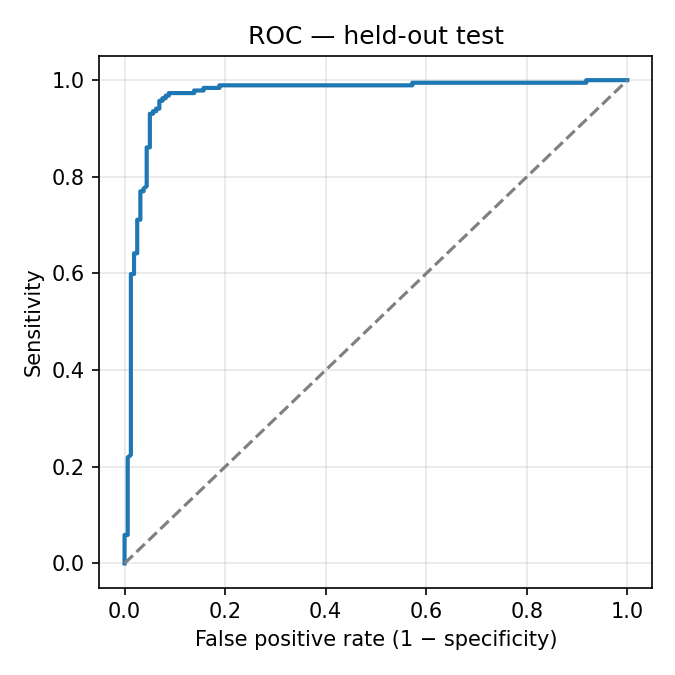

confusion_balanced.png


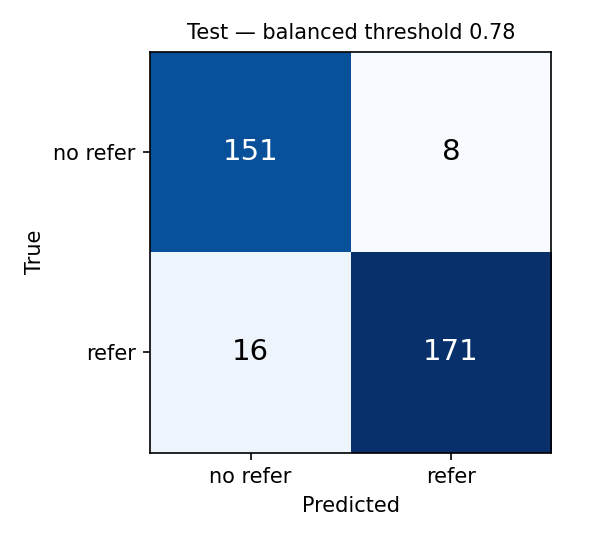

confusion_screening.png


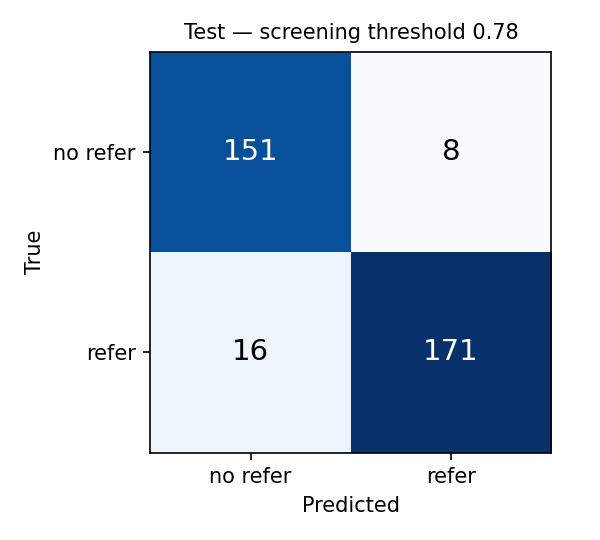

calibration_test.png


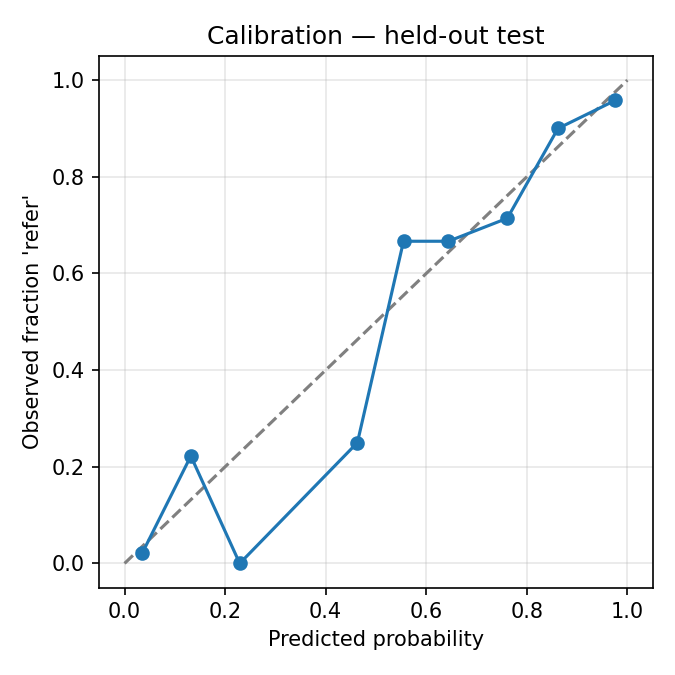

,source,n,refer,accuracy,sensitivity,specificity,auc
0,mohitmural/oral-cancer-lips-and-tongue,7,1,0.857143,1.000000,0.833333,0.833333
1,roboflow:aadith/ulcer_detection-12cr0,17,0,0.941176,0.000000,0.941176,NaN
2,roboflow:makhluk/leukoplakia-8woh8,43,43,0.953488,0.953488,0.000000,NaN
3,roboflow:oral-cancer-emoot/leukoplakia,7,7,0.857143,0.857143,0.000000,NaN
4,roboflow:oral-dquwv/oralleukoplakia,39,39,0.923077,0.923077,0.000000,NaN
5,salmansajid05/oral-diseases,42,0,0.928571,0.000000,0.928571,NaN
6,zaidpy/oral-cancer-dataset,191,97,0.931937,0.896907,0.968085,0.971266


In [19]:
import os
from IPython.display import Image, display

R = f"{cfg['paths']['work_dir']}/reports"

for f in [
    "roc_test.png",
    "confusion_balanced.png",
    "confusion_screening.png",
    "calibration_test.png",
    "heatmaps_test.png",
    "history_final.png"
]:
    if os.path.exists(f"{R}/{f}"):
        print(f)
        display(Image(f"{R}/{f}"))

pd.read_csv(f"{R}/per_source_test.csv")

In [20]:
import os
import zipfile
from pathlib import Path

R = Path(cfg["paths"]["work_dir"]) / "reports"

# Collect every PNG report
png_files = sorted(R.glob("*.png"))

print("PNG files found:", len(png_files))

# Create ZIP archive
ZIP_PATH = Path("/kaggle/working/OralScreen_Phase1_Plots.zip")

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z:
    for file in png_files:
        z.write(file, arcname=file.name)
        print("Saved:", file.name)

print("\nZIP created successfully!")
print("Location:", ZIP_PATH)
print("Archive size:", round(ZIP_PATH.stat().st_size / (1024 * 1024), 2), "MB")

PNG files found: 8
Saved: calibration_test.png
Saved: confusion_balanced.png
Saved: confusion_screening.png
Saved: heatmaps_test.png
Saved: history_convnext_tiny_fold0.png
Saved: history_dinov2_s_fold0.png
Saved: history_effnetv2_s_fold0.png
Saved: roc_test.png

ZIP created successfully!
Location: /kaggle/working/OralScreen_Phase1_Plots.zip
Archive size: 1.69 MB


In [21]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/OralScreen_Phase1_Plots.zip"))

/kaggle/working/OralScreen_Phase1_Plots.zip

In [22]:
import pandas as pd
import numpy as np

R = f"{cfg['paths']['work_dir']}/reports"
pred = pd.read_csv(f"{R}/test_predictions.csv")

print("Columns:", pred.columns.tolist())
print("\nDataset shape:", pred.shape)
display(pred.head(10))

print("\nClass distribution:")
display(pred["label"].value_counts(dropna=False))

Columns: ['path', 'source', 'label', 'reason', 'folder', 'drop_reason', 'md5', 'width', 'height', 'group', 'label_conflict', 'rep', 'orig_path', 'split', 'fold', 'prob', 'logit']

Dataset shape: (346, 17)


,path,source,label,reason,folder,drop_reason,md5,width,height,group,label_conflict,rep,orig_path,split,fold,prob,logit
0,/kaggle/working/oralscreen/image_cache/img_000...,zaidpy/oral-cancer-dataset,refer,refer keyword 'cancer' in 'cancer',Oral Cancer/Oral Cancer Dataset/CANCER,NaN,c720301019feb599f5cb6814b0047331,280,205,1,False,True,/kaggle/input/datasets/zaidpy/oral-cancer-data...,test,-1,0.809735,0.742188
1,/kaggle/working/oralscreen/image_cache/img_000...,zaidpy/oral-cancer-dataset,refer,refer keyword 'cancer' in 'cancer',Oral Cancer/Oral Cancer Dataset/CANCER,NaN,baac62f53085c53ab46aefb4dbbf71f3,280,205,3,False,True,/kaggle/input/datasets/zaidpy/oral-cancer-data...,test,-1,0.931762,1.653320
2,/kaggle/working/oralscreen/image_cache/img_000...,zaidpy/oral-cancer-dataset,refer,refer keyword 'cancer' in 'cancer',Oral Cancer/Oral Cancer Dataset/CANCER,NaN,a1cffd774c78f4437f7df4ab4ba2265d,280,205,4,False,True,/kaggle/input/datasets/zaidpy/oral-cancer-data...,test,-1,0.988163,3.068359
3,/kaggle/working/oralscreen/image_cache/img_000...,zaidpy/oral-cancer-dataset,refer,refer keyword 'cancer' in 'cancer',Oral Cancer/Oral Cancer Dataset/CANCER,NaN,284d8efc23b7f9584d617865ce60f2df,280,205,13,False,True,/kaggle/input/datasets/zaidpy/oral-cancer-data...,test,-1,0.985112,2.886719
4,/kaggle/working/oralscreen/image_cache/img_000...,zaidpy/oral-cancer-dataset,refer,refer keyword 'cancer' in 'cancer',Oral Cancer/Oral Cancer Dataset/CANCER,NaN,b9a879fc004bafaa0cfc73132bac72f9,280,205,21,False,True,/kaggle/input/datasets/zaidpy/oral-cancer-data...,test,-1,0.969528,2.314453
5,/kaggle/working/oralscreen/image_cache/img_000...,zaidpy/oral-cancer-dataset,refer,refer keyword 'cancer' in 'cancer',Oral Cancer/Oral Cancer Dataset/CANCER,NaN,721e5a042f0dee87a58f6635cb39ed04,280,205,22,False,True,/kaggle/input/datasets/zaidpy/oral-cancer-data...,test,-1,0.960650,2.107422
6,/kaggle/working/oralscreen/image_cache/img_000...,zaidpy/oral-cancer-dataset,refer,refer keyword 'cancer' in 'cancer',Oral Cancer/Oral Cancer Dataset/CANCER,NaN,3d8918bddefc1b8f8c92575c264981f9,280,205,33,False,True,/kaggle/input/datasets/zaidpy/oral-cancer-data...,test,-1,0.976908,2.537109
7,/kaggle/working/oralscreen/image_cache/img_000...,zaidpy/oral-cancer-dataset,refer,refer keyword 'cancer' in 'cancer',Oral Cancer/Oral Cancer Dataset/CANCER,NaN,00faf28779e8cd3efa4350c40a28b639,500,333,44,False,True,/kaggle/input/datasets/zaidpy/oral-cancer-data...,test,-1,0.986576,2.968750
8,/kaggle/working/oralscreen/image_cache/img_000...,zaidpy/oral-cancer-dataset,refer,refer keyword 'cancer' in 'cancer',Oral Cancer/Oral Cancer Dataset/CANCER,NaN,82584074817840c6faac2f58087f717c,480,360,88,False,True,/kaggle/input/datasets/zaidpy/oral-cancer-data...,test,-1,0.972813,2.406250
9,/kaggle/working/oralscreen/image_cache/img_000...,zaidpy/oral-cancer-dataset,refer,refer keyword 'cancer' in 'cancer',Oral Cancer/Oral Cancer Dataset/CANCER,NaN,9475d3b9a0ed78c5e37dd7305a891295,335,264,97,False,True,/kaggle/input/datasets/zaidpy/oral-cancer-data...,test,-1,0.962406,2.144531



Class distribution:


label
refer       187
no_refer    159
Name: count, dtype: int64

In [23]:
import pandas as pd
from pathlib import Path

R = Path(cfg["paths"]["work_dir"]) / "reports"

pred = pd.read_csv(R / "test_predictions.csv")

THRESHOLD = 0.7796038109379979

pred["predicted_label"] = pred["prob"].apply(
    lambda p: "refer" if p >= THRESHOLD else "no_refer"
)

# False negatives: actual refer, predicted no_refer
false_negatives = pred[
    (pred["label"] == "refer") &
    (pred["predicted_label"] == "no_refer")
].copy()

# False positives: actual no_refer, predicted refer
false_positives = pred[
    (pred["label"] == "no_refer") &
    (pred["predicted_label"] == "refer")
].copy()

print("FALSE NEGATIVES:", len(false_negatives))
display(false_negatives[
    ["source", "label", "prob", "orig_path", "width", "height"]
])

print("\nFALSE POSITIVES:", len(false_positives))
display(false_positives[
    ["source", "label", "prob", "orig_path", "width", "height"]
])

print("\nFalse negatives by source:")
display(false_negatives.groupby("source").size().reset_index(name="count"))

print("\nFalse positives by source:")
display(false_positives.groupby("source").size().reset_index(name="count"))

FALSE NEGATIVES: 16


,source,label,prob,orig_path,width,height
27,zaidpy/oral-cancer-dataset,refer,0.516576,/kaggle/input/datasets/zaidpy/oral-cancer-data...,504,623
39,zaidpy/oral-cancer-dataset,refer,0.120615,/kaggle/input/datasets/zaidpy/oral-cancer-data...,530,567
45,zaidpy/oral-cancer-dataset,refer,0.775824,/kaggle/input/datasets/zaidpy/oral-cancer-data...,859,764
51,zaidpy/oral-cancer-dataset,refer,0.754679,/kaggle/input/datasets/zaidpy/oral-cancer-data...,695,736
54,zaidpy/oral-cancer-dataset,refer,0.015836,/kaggle/input/datasets/zaidpy/oral-cancer-data...,338,304
70,zaidpy/oral-cancer-dataset,refer,0.539459,/kaggle/input/datasets/zaidpy/oral-cancer-data...,768,576
128,zaidpy/oral-cancer-dataset,refer,0.089664,/kaggle/input/datasets/zaidpy/oral-cancer-data...,1224,1280
130,zaidpy/oral-cancer-dataset,refer,0.032301,/kaggle/input/datasets/zaidpy/oral-cancer-data...,340,226
133,zaidpy/oral-cancer-dataset,refer,0.590203,/kaggle/input/datasets/zaidpy/oral-cancer-data...,234,215
140,zaidpy/oral-cancer-dataset,refer,0.159695,/kaggle/input/datasets/zaidpy/oral-cancer-data...,800,553



FALSE POSITIVES: 8


,source,label,prob,orig_path,width,height
158,zaidpy/oral-cancer-dataset,no_refer,0.976624,/kaggle/input/datasets/zaidpy/oral-cancer-data...,1039,577
159,zaidpy/oral-cancer-dataset,no_refer,0.962134,/kaggle/input/datasets/zaidpy/oral-cancer-data...,605,577
162,zaidpy/oral-cancer-dataset,no_refer,0.897454,/kaggle/input/datasets/zaidpy/oral-cancer-data...,770,577
196,mohitmural/oral-cancer-lips-and-tongue,no_refer,0.993203,/kaggle/input/datasets/mohitmural/oral-cancer-...,798,598
218,salmansajid05/oral-diseases,no_refer,0.948654,/kaggle/input/datasets/salmansajid05/oral-dise...,270,186
219,salmansajid05/oral-diseases,no_refer,0.973011,/kaggle/input/datasets/salmansajid05/oral-dise...,300,168
238,salmansajid05/oral-diseases,no_refer,0.945007,/kaggle/input/datasets/salmansajid05/oral-dise...,269,188
342,roboflow:aadith/ulcer_detection-12cr0,no_refer,0.989565,/kaggle/working/roboflow/aadith__ulcer_detecti...,224,224



False negatives by source:


,source,count
0,roboflow:makhluk/leukoplakia-8woh8,2
1,roboflow:oral-cancer-emoot/leukoplakia,1
2,roboflow:oral-dquwv/oralleukoplakia,3
3,zaidpy/oral-cancer-dataset,10



False positives by source:


,source,count
0,mohitmural/oral-cancer-lips-and-tongue,1
1,roboflow:aadith/ulcer_detection-12cr0,1
2,salmansajid05/oral-diseases,3
3,zaidpy/oral-cancer-dataset,3


In [25]:
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd
import math

errors = pd.concat([
    false_negatives.assign(error_type="FALSE NEGATIVE"),
    false_positives.assign(error_type="FALSE POSITIVE")
]).reset_index(drop=True)

n = len(errors)
cols = 3
rows = math.ceil(n / cols)

fig, axes = plt.subplots(
    rows, cols,
    figsize=(18, rows * 5),
    constrained_layout=True
)

axes = axes.flatten()

for i, (_, row) in enumerate(errors.iterrows()):
    ax = axes[i]

    try:
        img = Image.open(row["orig_path"]).convert("RGB")
        ax.imshow(img)
        ax.set_title(
            f'{row["error_type"]}\n'
            f'True: {row["label"]} | P(refer): {row["prob"]:.3f}\n'
            f'Source: {row["source"].split("/")[-1]}',
            fontsize=9,
            pad=8
        )
    except Exception as e:
        ax.text(0.5, 0.5, f"Image unavailable: {e}",
                ha="center", va="center")

    ax.axis("off")

for ax in axes[n:]:
    ax.axis("off")

fig.suptitle(
    "OralScreen — All 24 Misclassified Test Images",
    fontsize=18
)

fig.savefig(
    "/kaggle/working/OralScreen_Misclassified_Images.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved: /kaggle/working/OralScreen_Misclassified_Images.png")

/tmp/ipykernel_49/382090917.py:50: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(


Saved: /kaggle/working/OralScreen_Misclassified_Images.png


/usr/local/lib/python3.13/dist-packages/IPython/core/events.py:89: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)


In [26]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import math

OUT = Path("/kaggle/working/oralscreen_error_analysis")
OUT.mkdir(parents=True, exist_ok=True)

def make_error_sheet(df, title, filename):
    n = len(df)
    cols = 4
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(18, rows * 4.5)
    )
    axes = axes.flatten()

    for i, (_, row) in enumerate(df.iterrows()):
        ax = axes[i]

        try:
            # Use the actual cached image used by the model.
            img = Image.open(row["path"]).convert("RGB")
            ax.imshow(img)

            ax.set_title(
                f'{row["source"].split("/")[-1]}\n'
                f'True: {row["label"]} | '
                f'P(refer): {row["prob"]:.3f}',
                fontsize=9
            )

        except Exception as e:
            ax.text(0.5, 0.5, str(e),
                    ha="center", va="center")

        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    fig.suptitle(title, fontsize=17)
    fig.tight_layout(rect=[0, 0, 1, 0.97])

    save_path = OUT / filename
    fig.savefig(save_path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved:", save_path)


make_error_sheet(
    false_negatives,
    "OralScreen — False Negatives (16 images)",
    "false_negatives.png"
)

make_error_sheet(
    false_positives,
    "OralScreen — False Positives (8 images)",
    "false_positives.png"
)

Saved: /kaggle/working/oralscreen_error_analysis/false_negatives.png
Saved: /kaggle/working/oralscreen_error_analysis/false_positives.png


In [27]:
import pandas as pd

errors = pd.concat([
    false_negatives.assign(error_type="FALSE_NEGATIVE"),
    false_positives.assign(error_type="FALSE_POSITIVE")
]).copy()

cols = [
    "error_type",
    "source",
    "label",
    "reason",
    "folder",
    "drop_reason",
    "orig_path",
    "prob",
    "width",
    "height"
]

display(
    errors[cols]
    .sort_values(["source", "error_type"])
    .reset_index(drop=True)
)

,error_type,source,label,reason,folder,drop_reason,orig_path,prob,width,height
0,FALSE_POSITIVE,mohitmural/oral-cancer-lips-and-tongue,no_refer,no_refer keyword 'non cancer' in 'non cancer',OralCancer/non-cancer,NaN,/kaggle/input/datasets/mohitmural/oral-cancer-...,0.993203,798,598
1,FALSE_POSITIVE,roboflow:aadith/ulcer_detection-12cr0,no_refer,roboflow project label (recurrent aphthous ulc...,train/images,NaN,/kaggle/working/roboflow/aadith__ulcer_detecti...,0.989565,224,224
2,FALSE_NEGATIVE,roboflow:makhluk/leukoplakia-8woh8,refer,roboflow project label (oral leukoplakia),test/images,NaN,/kaggle/working/roboflow/makhluk__leukoplakia-...,0.477082,640,640
3,FALSE_NEGATIVE,roboflow:makhluk/leukoplakia-8woh8,refer,roboflow project label (oral leukoplakia),valid/images,NaN,/kaggle/working/roboflow/makhluk__leukoplakia-...,0.579928,640,640
4,FALSE_NEGATIVE,roboflow:oral-cancer-emoot/leukoplakia,refer,roboflow project label (oral leukoplakia),valid/images,NaN,/kaggle/working/roboflow/oral-cancer-emoot__le...,0.663319,640,640
5,FALSE_NEGATIVE,roboflow:oral-dquwv/oralleukoplakia,refer,roboflow project label (oral leukoplakia),train/images,NaN,/kaggle/working/roboflow/oral-dquwv__oralleuko...,0.778097,256,256
6,FALSE_NEGATIVE,roboflow:oral-dquwv/oralleukoplakia,refer,roboflow project label (oral leukoplakia),train/images,NaN,/kaggle/working/roboflow/oral-dquwv__oralleuko...,0.625052,256,256
7,FALSE_NEGATIVE,roboflow:oral-dquwv/oralleukoplakia,refer,roboflow project label (oral leukoplakia),train/images,NaN,/kaggle/working/roboflow/oral-dquwv__oralleuko...,0.764321,576,1280
8,FALSE_POSITIVE,salmansajid05/oral-diseases,no_refer,no_refer keyword 'mouth ulcer' in 'mouth ulcer',Mouth Ulcer/Mouth Ulcer/ulcer original dataset...,NaN,/kaggle/input/datasets/salmansajid05/oral-dise...,0.948654,270,186
9,FALSE_POSITIVE,salmansajid05/oral-diseases,no_refer,no_refer keyword 'mouth ulcer' in 'mouth ulcer',Mouth Ulcer/Mouth Ulcer/ulcer original dataset...,NaN,/kaggle/input/datasets/salmansajid05/oral-dise...,0.973011,300,168


In [30]:
import pandas as pd
from pathlib import Path

manifest_path = Path(
    "/kaggle/working/oralscreen/manifest_split.pkl"
)

df = pd.read_pickle(manifest_path)

print("Total manifest rows:", len(df))

# 1. Source × label distribution
print("\n========== SOURCE × LABEL ==========")
display(pd.crosstab(df["source"], df["label"], margins=True))

# 2. Label assignment reasons
print("\n========== LABEL ASSIGNMENT REASONS ==========")
display(
    df.groupby(
        ["source", "label", "reason"],
        dropna=False
    ).size().reset_index(name="count")
    .sort_values(["source", "label"])
)

# 3. Folder-level label distribution
print("\n========== FOLDER × LABEL ==========")
display(
    df.groupby(
        ["source", "folder", "label"],
        dropna=False
    ).size().reset_index(name="count")
    .sort_values(["source", "folder", "label"])
)

# 4. Split × source × label distribution
print("\n========== SPLIT × SOURCE × LABEL ==========")
display(
    df.groupby(
        ["split", "source", "label"]
    ).size().reset_index(name="count")
)

Total manifest rows: 8313

========== SOURCE × LABEL ==========


label,no_refer,refer,All
source,,,
Teeth_Dataset,2794,2338,5132
mohitmural/oral-cancer-lips-and-tongue,41,84,125
roboflow:aadith/ulcer_detection-12cr0,384,0,384
roboflow:makhluk/leukoplakia-8woh8,0,232,232
roboflow:oral-cancer-emoot/leukoplakia,0,74,74
roboflow:oral-dquwv/oralleukoplakia,0,412,412
salmansajid05/oral-diseases,263,0,263
zaidpy/oral-cancer-dataset,699,992,1691
All,4181,4132,8313



========== LABEL ASSIGNMENT REASONS ==========


,source,label,reason,count
0,Teeth_Dataset,no_refer,exact folder 'cas',793
1,Teeth_Dataset,no_refer,exact folder 'cos',747
2,Teeth_Dataset,no_refer,exact folder 'gum',600
3,Teeth_Dataset,no_refer,exact folder 'ot',654
4,Teeth_Dataset,refer,exact folder 'mc',900
5,Teeth_Dataset,refer,exact folder 'oc',538
6,Teeth_Dataset,refer,exact folder 'olp',900
7,mohitmural/oral-cancer-lips-and-tongue,no_refer,no_refer keyword 'non cancer' in 'non cancer',41
8,mohitmural/oral-cancer-lips-and-tongue,refer,refer keyword 'cancer' in 'cancer',84
9,roboflow:aadith/ulcer_detection-12cr0,no_refer,roboflow project label (recurrent aphthous ulc...,384



========== FOLDER × LABEL ==========


,source,folder,label,count
0,Teeth_Dataset,Testing/CaS,no_refer,158
1,Teeth_Dataset,Testing/CoS,no_refer,149
2,Teeth_Dataset,Testing/Gum,no_refer,120
3,Teeth_Dataset,Testing/MC,refer,180
4,Teeth_Dataset,Testing/OC,refer,107
5,Teeth_Dataset,Testing/OLP,refer,180
6,Teeth_Dataset,Testing/OT,no_refer,130
7,Teeth_Dataset,Training/CaS,no_refer,477
8,Teeth_Dataset,Training/CoS,no_refer,450
9,Teeth_Dataset,Training/Gum,no_refer,360



========== SPLIT × SOURCE × LABEL ==========


,split,source,label,count
0,calib,mohitmural/oral-cancer-lips-and-tongue,no_refer,4
1,calib,mohitmural/oral-cancer-lips-and-tongue,refer,2
2,calib,roboflow:aadith/ulcer_detection-12cr0,no_refer,47
3,calib,roboflow:makhluk/leukoplakia-8woh8,refer,24
4,calib,roboflow:oral-cancer-emoot/leukoplakia,refer,6
5,calib,roboflow:oral-dquwv/oralleukoplakia,refer,41
6,calib,salmansajid05/oral-diseases,no_refer,30
7,calib,zaidpy/oral-cancer-dataset,no_refer,93
8,calib,zaidpy/oral-cancer-dataset,refer,94
9,dev,Teeth_Dataset,no_refer,2794


In [31]:
import pandas as pd

df = pd.read_pickle(
    "/kaggle/working/oralscreen/manifest_split.pkl"
)

test = df[(df["split"] == "test") & (df["rep"] == True)].copy()

print("Unique held-out test representatives:", len(test))

print("\n========== TEST SOURCE DISTRIBUTION ==========")
display(
    pd.crosstab(test["source"], test["label"], margins=True)
)

print("\n========== TEST SOURCE COUNTS ==========")
display(
    test.groupby("source").agg(
        images=("path", "count"),
        refer=("label", lambda x: (x == "refer").sum()),
        no_refer=("label", lambda x: (x == "no_refer").sum())
    ).sort_values("images", ascending=False)
)

Unique held-out test representatives: 346

========== TEST SOURCE DISTRIBUTION ==========


label,no_refer,refer,All
source,,,
mohitmural/oral-cancer-lips-and-tongue,6,1,7
roboflow:aadith/ulcer_detection-12cr0,17,0,17
roboflow:makhluk/leukoplakia-8woh8,0,43,43
roboflow:oral-cancer-emoot/leukoplakia,0,7,7
roboflow:oral-dquwv/oralleukoplakia,0,39,39
salmansajid05/oral-diseases,42,0,42
zaidpy/oral-cancer-dataset,94,97,191
All,159,187,346



========== TEST SOURCE COUNTS ==========


,images,refer,no_refer
source,,,
zaidpy/oral-cancer-dataset,191,97,94
roboflow:makhluk/leukoplakia-8woh8,43,43,0
salmansajid05/oral-diseases,42,0,42
roboflow:oral-dquwv/oralleukoplakia,39,39,0
roboflow:aadith/ulcer_detection-12cr0,17,0,17
mohitmural/oral-cancer-lips-and-tongue,7,1,6
roboflow:oral-cancer-emoot/leukoplakia,7,7,0


In [32]:
import pandas as pd
import numpy as np
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix
)

R = f"{cfg['paths']['work_dir']}/reports"
pred = pd.read_csv(f"{R}/test_predictions.csv")

threshold = 0.7796038109379979

pred["predicted"] = (
    pred["prob"] >= threshold
).astype(int)

pred["actual"] = (
    pred["label"] == "refer"
).astype(int)

results = []

for source, group in pred.groupby("source"):
    y = group["actual"].values
    p = group["predicted"].values
    scores = group["prob"].values

    tn, fp, fn, tp = confusion_matrix(
        y, p, labels=[0, 1]
    ).ravel()

    results.append({
        "source": source,
        "n": len(group),
        "refer": int(y.sum()),
        "no_refer": int((y == 0).sum()),
        "accuracy": accuracy_score(y, p),
        "sensitivity": tp / (tp + fn) if tp + fn else np.nan,
        "specificity": tn / (tn + fp) if tn + fp else np.nan,
        "balanced_accuracy": balanced_accuracy_score(y, p)
            if len(np.unique(y)) == 2 else np.nan,
        "AUC": roc_auc_score(y, scores)
            if len(np.unique(y)) == 2 else np.nan
    })

display(
    pd.DataFrame(results).round(4)
)

,source,n,refer,no_refer,accuracy,sensitivity,specificity,balanced_accuracy,AUC
0,mohitmural/oral-cancer-lips-and-tongue,7,1,6,0.8571,1.0000,0.8333,0.9167,0.8333
1,roboflow:aadith/ulcer_detection-12cr0,17,0,17,0.9412,NaN,0.9412,NaN,NaN
2,roboflow:makhluk/leukoplakia-8woh8,43,43,0,0.9535,0.9535,NaN,NaN,NaN
3,roboflow:oral-cancer-emoot/leukoplakia,7,7,0,0.8571,0.8571,NaN,NaN,NaN
4,roboflow:oral-dquwv/oralleukoplakia,39,39,0,0.9231,0.9231,NaN,NaN,NaN
5,salmansajid05/oral-diseases,42,0,42,0.9286,NaN,0.9286,NaN,NaN
6,zaidpy/oral-cancer-dataset,191,97,94,0.9319,0.8969,0.9681,0.9325,0.9713


In [33]:
from pathlib import Path

ROOT = Path("/kaggle/working")

important_paths = [
    ROOT / "oralscreen",
    ROOT / "oralscreen-phase1",
    ROOT / "checkpoint_metadata",
    ROOT / "extra_data" / "mod-original",
    ROOT / "oralscreen_error_analysis",
]

print("PHASE 1 CHECKPOINT INVENTORY\n")

total_bytes = 0

for folder in important_paths:
    if not folder.exists():
        print(f"MISSING: {folder}")
        continue

    files = [p for p in folder.rglob("*") if p.is_file()]
    size = sum(p.stat().st_size for p in files)
    total_bytes += size

    print(f"{folder}")
    print(f"  Files: {len(files):,}")
    print(f"  Size:  {size / (1024**3):.2f} GB")

print("\nIMPORTANT REPORTS")
reports = ROOT / "oralscreen" / "reports"

for name in [
    "cross_validation.csv",
    "cross_validation.json",
    "test_predictions.csv",
]:
    p = reports / name
    print(f"{'OK' if p.exists() else 'MISSING'}: {p}")

print("\nTOTAL ESTIMATED SIZE")
print(f"{total_bytes / (1024**3):.2f} GB")

PHASE 1 CHECKPOINT INVENTORY

/kaggle/working/oralscreen
  Files: 8,345
  Size:  0.34 GB
/kaggle/working/oralscreen-phase1
  Files: 31
  Size:  0.00 GB
/kaggle/working/checkpoint_metadata
  Files: 3
  Size:  0.00 GB
/kaggle/working/extra_data/mod-original
  Files: 5,144
  Size:  0.09 GB
/kaggle/working/oralscreen_error_analysis
  Files: 2
  Size:  0.01 GB

IMPORTANT REPORTS
OK: /kaggle/working/oralscreen/reports/cross_validation.csv
OK: /kaggle/working/oralscreen/reports/cross_validation.json
OK: /kaggle/working/oralscreen/reports/test_predictions.csv

TOTAL ESTIMATED SIZE
0.44 GB


In [34]:
import tarfile
import hashlib
from pathlib import Path
from datetime import datetime

ROOT = Path("/kaggle/working")

folders = [
    "oralscreen",
    "oralscreen-phase1",
    "checkpoint_metadata",
    "extra_data/mod-original",
    "oralscreen_error_analysis",
]

archive = ROOT / "oralscreen_phase1_final_checkpoint.tar.gz"

# Create archive
print("Creating Phase 1 checkpoint...")

with tarfile.open(archive, "w:gz", compresslevel=4) as tar:
    for folder in folders:
        path = ROOT / folder
        if not path.exists():
            raise FileNotFoundError(f"Missing checkpoint directory: {path}")

        tar.add(path, arcname=folder)

print("\nArchive created.")

# Calculate SHA-256
print("Calculating SHA-256...")
sha256 = hashlib.sha256()

with open(archive, "rb") as f:
    for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
        sha256.update(chunk)

checksum = sha256.hexdigest()

# Verify archive integrity
print("Verifying archive...")

with tarfile.open(archive, "r:gz") as tar:
    members = tar.getmembers()
    bad_member = tarfile.TarFile.extractfile

    required = [
        "oralscreen/reports/cross_validation.csv",
        "oralscreen/reports/cross_validation.json",
        "oralscreen/reports/test_predictions.csv",
        "oralscreen_phase1",
        "checkpoint_metadata/effective_config.yaml",
    ]

    names = set(tar.getnames())

    for item in required:
        if item not in names:
            raise RuntimeError(f"Missing from archive: {item}")

    # Read every archived file to verify gzip/tar integrity
    for member in members:
        if member.isfile():
            extracted = tar.extractfile(member)
            while extracted.read(8 * 1024 * 1024):
                pass

print("\n" + "=" * 55)
print("PHASE 1 CHECKPOINT VERIFIED")
print("=" * 55)
print(f"Archive: {archive}")
print(f"Size:    {archive.stat().st_size / (1024**3):.3f} GB")
print(f"Files:   {sum(m.isfile() for m in members):,}")
print(f"SHA256:  {checksum}")
print("Integrity: PASSED")

Creating Phase 1 checkpoint...

Archive created.
Calculating SHA-256...
Verifying archive...


RuntimeError: Missing from archive: oralscreen_phase1

In [35]:
import tarfile
import hashlib
from pathlib import Path

archive = Path("/kaggle/working/oralscreen_phase1_final_checkpoint.tar.gz")

if not archive.exists():
    raise FileNotFoundError(archive)

print("Verifying existing archive...")

with tarfile.open(archive, "r:gz") as tar:
    members = tar.getmembers()
    names = set(tar.getnames())

    required = [
        "oralscreen/reports/cross_validation.csv",
        "oralscreen/reports/cross_validation.json",
        "oralscreen/reports/test_predictions.csv",
        "oralscreen-phase1",
        "checkpoint_metadata/effective_config.yaml",
        "extra_data/mod-original/Teeth_Dataset",
        "oralscreen_error_analysis/false_negatives.png",
        "oralscreen_error_analysis/false_positives.png",
    ]

    missing = [item for item in required if item not in names]

    if missing:
        raise RuntimeError(f"Missing archive contents: {missing}")

    # Read all files to verify archive integrity
    for member in members:
        if member.isfile():
            with tar.extractfile(member) as f:
                while f.read(8 * 1024 * 1024):
                    pass

print("Archive contents and integrity: PASSED")

sha256 = hashlib.sha256()

with open(archive, "rb") as f:
    for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
        sha256.update(chunk)

print("\nCHECKPOINT DETAILS")
print("Archive:", archive)
print(f"Size: {archive.stat().st_size / (1024**3):.3f} GB")
print(f"Files: {sum(m.isfile() for m in members):,}")
print("SHA-256:", sha256.hexdigest())

Verifying existing archive...
Archive contents and integrity: PASSED

CHECKPOINT DETAILS
Archive: /kaggle/working/oralscreen_phase1_final_checkpoint.tar.gz
Size: 0.374 GB
Files: 13,525
SHA-256: cdd814e456bd9fddec671e0ca53bfab165d5de5635301df33a81ba0a3da68d65


In [36]:
from pathlib import Path

ROOT = Path("/kaggle/working/oralscreen")

print("SEARCHING FOR FINAL MODEL WEIGHTS\n")

extensions = {".pth", ".pt", ".ckpt", ".safetensors", ".bin"}

files = [
    p for p in ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

for p in files:
    print(f"{p.relative_to(ROOT)}  |  {p.stat().st_size / (1024**2):.2f} MB")

if not files:
    print("No model weight files found.")

SEARCHING FOR FINAL MODEL WEIGHTS

artifacts/checkpoints/lesion_model.pt  |  77.84 MB


In [37]:
from pathlib import Path
import torch

checkpoint_path = Path(
    "/kaggle/working/oralscreen/artifacts/checkpoints/lesion_model.pt"
)

assert checkpoint_path.exists(), "Model checkpoint not found!"

print("Checkpoint:", checkpoint_path)
print("File size:", round(checkpoint_path.stat().st_size / (1024**2), 2), "MB")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

# Load checkpoint safely for inspection
try:
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )
except Exception as e:
    print("Safe loading failed:", repr(e))
    raise

print("\nCHECKPOINT TYPE:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCHECKPOINT KEYS:")
    for key, value in checkpoint.items():
        if isinstance(value, dict):
            print(f"{key}: dictionary ({len(value)} entries)")
        elif isinstance(value, torch.Tensor):
            print(f"{key}: Tensor {tuple(value.shape)}")
        else:
            print(f"{key}: {type(value).__name__} = {str(value)[:150]}")

    print("\nPOSSIBLE MODEL STATE DICTIONARY:")
    for key, value in checkpoint.items():
        if isinstance(value, dict) and value:
            tensor_count = sum(
                isinstance(v, torch.Tensor) for v in value.values()
            )
            if tensor_count:
                print(f"{key}: {tensor_count} tensors")

Checkpoint: /kaggle/working/oralscreen/artifacts/checkpoints/lesion_model.pt
File size: 77.84 MB
PyTorch: 2.11.0+cu130
CUDA available: True

CHECKPOINT TYPE: <class 'dict'>

CHECKPOINT KEYS:
state_dict: dictionary (782 entries)
timm: str = tf_efficientnetv2_s.in21k_ft_in1k
candidate: dictionary (6 entries)
image_size: int = 224
calibration: dictionary (2 entries)
thresholds: dictionary (2 entries)
best_epoch: int = 7

POSSIBLE MODEL STATE DICTIONARY:
state_dict: 782 tensors


In [39]:
%pip install -q onnxruntime

import onnxruntime as ort

print("ONNX Runtime installed successfully")
print("Version:", ort.__version__)
print("Available providers:", ort.get_available_providers())

Note: you may need to restart the kernel to use updated packages.
ONNX Runtime installed successfully
Version: 1.31.1
Available providers: ['AzureExecutionProvider', 'CPUExecutionProvider']


In [40]:
print("Running final ONNX export, verification and packaging...")

pipe.run(["export", "verify", "package"])

print("\nFINAL PIPELINE COMPLETED")



Running final ONNX export, verification and packaging...


16:05:31 | INFO    | ▶ export ONNX + INT8
16:06:45 | INFO    | ONNX parity: {'full_fp32': {'max_abs_diff_vs_torch': 1.3709068298339844e-06, 'auc': 0.9598378776713339}, 'full_int8': {'max_abs_diff_vs_torch': 0.0032264888286590576, 'auc': 0.9597764676983542}, 'int8_auc_drop': 6.140997297965356e-05, 'int8_recommended': True}
16:06:45 | INFO    | ✔ export ONNX + INT8 (73.9s)
16:06:45 | INFO    | ▶ out-of-distribution stats + reference embeddings
16:07:18 | INFO    | ✔ out-of-distribution stats + reference embeddings (33.0s)
16:07:18 | INFO    | ▶ benchmark set
16:07:19 | INFO    | Benchmark set: 346 images (fixed; never used for training)
16:07:19 | INFO    | ✔ benchmark set (1.0s)
16:07:19 | INFO    | ▶ verify exported artifacts (standalone reference inference)
16:08:44 | INFO    | ✔ verify exported artifacts (standalone reference inference) (85.2s)
16:08:44 | INFO    | Artifact verification: {'n': 346, 'full_vs_backbone_head_max_diff': 1.1920928955078125e-07, 'fp32_vs_int8_max_diff': 0.0


FINAL PIPELINE COMPLETED


In [41]:
import shutil, os
from pathlib import Path
art = Path(pipe.art); out = Path("/kaggle/working/slim/current")
shutil.rmtree(out.parent, ignore_errors=True)
skip = {"checkpoints", "lesion_model.onnx"}      # PyTorch checkpoint + duplicate FP32 full model
shutil.copytree(art, out, ignore=lambda d, names: [n for n in names if n in skip])
shutil.make_archive("/kaggle/working/oralscreen_model_slim", "zip", root_dir=out.parent)
print(round(os.path.getsize("/kaggle/working/oralscreen_model_slim.zip")/1e6, 1), "MB")

357.8 MB


In [12]:
print("hello")

hello


## Done
Download **`oralscreen_artifacts.zip`** from the Output panel (right side → `/kaggle/working`).
That zip is what goes into Phase 2 (`models/current/`).

If you want me to tune anything, send me: `reports/test_metrics.json`, `reports/scan_report.csv`,
`reports/candidate_selection.csv` and `pipeline.log` (all inside the zip / `/kaggle/working/oralscreen`).